## 1. Setup and imports

In [1]:
# Run this cell ONCE if the versions printed in the next cell are too old, then use Kernel -> Restart.
# %pip install -q "numpy<2" "scipy>=1.11" "matplotlib>=3.7,<3.10" "seaborn>=0.13" "scikit-learn>=1.3,<1.7"

In [2]:
# Check the library versions (needed: scikit-learn 1.3 or newer, seaborn 0.13 with matplotlib 3.7-3.9).
import sys, numpy, pandas, matplotlib, seaborn, sklearn
print("Python      ", sys.version.split()[0])
print("numpy       ", numpy.__version__)
print("pandas      ", pandas.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", seaborn.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.10.0
numpy        2.2.6
pandas       2.3.3
matplotlib   3.10.9
seaborn      0.13.2
scikit-learn 1.7.2


In [3]:
import pandas as pd               # tables (DataFrames)
import numpy as np                # numerical operations and arrays
import matplotlib.pyplot as plt   # basic plotting
import seaborn as sns             # nicer statistical plots, built on matplotlib
from pathlib import Path          # working with folders and file paths
import warnings

pd.set_option("display.max_columns", 30)   # show all columns when printing a table
sns.set_theme()                            # seaborn's default plot style

# Folders used by the whole notebook (the notebook is run from the notebooks/ folder)
DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
RESULTS_DIR = Path("../results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Readable names for the 8 leagues (LeagueIndex 1-8)
league_names = {1: "Bronze", 2: "Silver", 3: "Gold", 4: "Platinum",
                5: "Diamond", 6: "Master", 7: "GrandMaster", 8: "Professional"}
target_names = list(league_names.values())

# Hide convergence warnings: some experiments deliberately use few iterations
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

print("Setup complete.")
print("CSV files found:", list(DATA_DIR.rglob("*.csv")))

Setup complete.
CSV files found: [WindowsPath('../data/dota2Test.csv'), WindowsPath('../data/dota2Train.csv'), WindowsPath('../data/SkillCraft1_Dataset.csv')]


## 2. Load, clean and explore the data
### 2.1 Load and inspect

In [4]:
# Load SkillCraft into a pandas DataFrame and look at the first rows.
df = pd.read_csv(DATA_DIR / "SkillCraft1_Dataset.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (3395, 20)


,GameID,LeagueIndex,Age,HoursPerWeek,TotalHours,APM,SelectByHotkeys,AssignToHotkeys,UniqueHotkeys,MinimapAttacks,MinimapRightClicks,NumberOfPACs,GapBetweenPACs,ActionLatency,ActionsInPAC,TotalMapExplored,WorkersMade,UniqueUnitsMade,ComplexUnitsMade,ComplexAbilitiesUsed
0,52,5,27,10,3000,143.7180,0.003515,0.000220,7,0.000110,0.000392,0.004849,32.6677,40.8673,4.7508,28,0.001397,6,0.0,0.000000
1,55,5,23,10,5000,129.2322,0.003304,0.000259,4,0.000294,0.000432,0.004307,32.9194,42.3454,4.8434,22,0.001193,5,0.0,0.000208
2,56,4,30,10,200,69.9612,0.001101,0.000336,4,0.000294,0.000461,0.002926,44.6475,75.3548,4.0430,22,0.000745,6,0.0,0.000189
3,57,3,19,20,400,107.6016,0.001034,0.000213,1,0.000053,0.000543,0.003783,29.2203,53.7352,4.9155,19,0.000426,7,0.0,0.000384
4,58,3,32,10,500,122.8908,0.001136,0.000327,2,0.000000,0.001329,0.002368,22.6885,62.0813,9.3740,15,0.001174,4,0.0,0.000019


In [5]:
# Data type of each column: Age, HoursPerWeek and TotalHours are 'object' (text), not numbers. Why?
df.dtypes

GameID                    int64
LeagueIndex               int64
Age                      object
HoursPerWeek             object
TotalHours               object
APM                     float64
SelectByHotkeys         float64
AssignToHotkeys         float64
UniqueHotkeys             int64
MinimapAttacks          float64
MinimapRightClicks      float64
NumberOfPACs            float64
GapBetweenPACs          float64
ActionLatency           float64
ActionsInPAC            float64
TotalMapExplored          int64
WorkersMade             float64
UniqueUnitsMade           int64
ComplexUnitsMade        float64
ComplexAbilitiesUsed    float64
dtype: object

In [6]:
# Attempt to convert the suspicious columns to numbers.
# Any value that cannot be converted becomes NaN, so we can see what it was.
for col in ["Age", "HoursPerWeek", "TotalHours"]:
    converted = pd.to_numeric(df[col], errors="coerce")
    bad = df[col][converted.isna()]
    print(col, "| non-numeric count:", len(bad), "| values:", bad.unique())

Age | non-numeric count: 55 | values: ['?']
HoursPerWeek | non-numeric count: 56 | values: ['?']
TotalHours | non-numeric count: 57 | values: ['?']


### 2.2 Missing values: which players are affected?

In [7]:
# Reload the file, this time telling pandas that '?' means "missing".
df = pd.read_csv(DATA_DIR / "SkillCraft1_Dataset.csv", na_values="?")
print("Missing values per column:")
print(df.isna().sum()[lambda s: s > 0])

# Count how many of the three values are missing for each player, per league.
cols = ["Age", "HoursPerWeek", "TotalHours"]
n_missing = df[cols].isna().sum(axis=1)
print("\nNumber of missing values per player (columns) by league (rows):")
print(pd.crosstab(df["LeagueIndex"].map(league_names), n_missing).reindex(target_names))

Missing values per column:
Age             55
HoursPerWeek    56
TotalHours      57
dtype: int64

Number of missing values per player (columns) by league (rows):
col_0           0  1  2   3
LeagueIndex                
Bronze        167  0  0   0
Silver        347  0  0   0
Gold          553  0  0   0
Platinum      811  0  0   0
Diamond       804  1  1   0
Master        621  0  0   0
GrandMaster    35  0  0   0
Professional    0  0  0  55


In [8]:
# Other checks: duplicates and an extreme value in TotalHours.
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate GameIDs:", df["GameID"].duplicated().sum())
print("Largest TotalHours values:", df["TotalHours"].nlargest(3).tolist())

Duplicate rows: 0
Duplicate GameIDs: 0
Largest TotalHours values: [1000000.0, 25000.0, 20000.0]


**Decision.** All 55 Professional players are missing all three demographic columns. Deleting those rows would delete the whole Professional class, and filling them in (imputing) would invent values for an entire class. We therefore **drop `Age`, `HoursPerWeek` and `TotalHours`**, plus the identifier `GameID`, and keep all 3,395 players with 15 complete gameplay features. `TotalHours` also contains an impossible value (1,000,000 hours). There are no categorical input features: all 15 are numeric.

In [9]:
# X = the 15 clean gameplay features, y = the league (target).
drop_cols = ["GameID", "Age", "HoursPerWeek", "TotalHours"]
X = df.drop(columns=drop_cols + ["LeagueIndex"])
y = df["LeagueIndex"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values left in X:", X.isna().sum().sum())
print(X.columns.tolist())

X shape: (3395, 15)
y shape: (3395,)
Missing values left in X: 0
['APM', 'SelectByHotkeys', 'AssignToHotkeys', 'UniqueHotkeys', 'MinimapAttacks', 'MinimapRightClicks', 'NumberOfPACs', 'GapBetweenPACs', 'ActionLatency', 'ActionsInPAC', 'TotalMapExplored', 'WorkersMade', 'UniqueUnitsMade', 'ComplexUnitsMade', 'ComplexAbilitiesUsed']


### 2.3 Class distribution

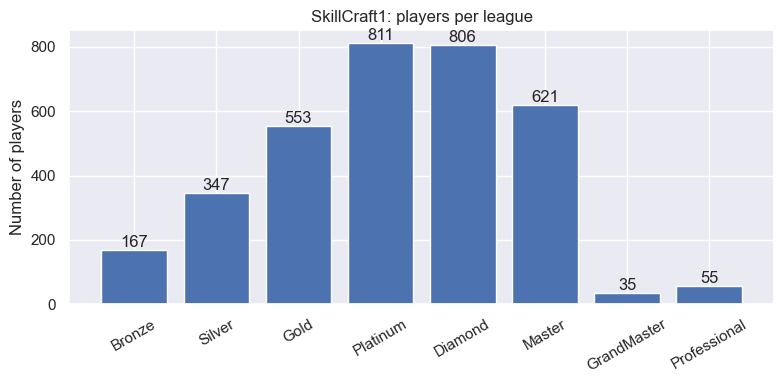

LeagueIndex
1    0.049
2    0.102
3    0.163
4    0.239
5    0.237
6    0.183
7    0.010
8    0.016
Name: count, dtype: float64


In [10]:
# Count and plot the number of players in each league.
counts = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([league_names[i] for i in counts.index], counts.values)
ax.bar_label(bars)
ax.set_ylabel("Number of players")
ax.set_title("SkillCraft1: players per league")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "skillcraft_league_distribution.png", dpi=150)
plt.show()

print((counts / counts.sum()).round(3))

The leagues are strongly **imbalanced**: Platinum and Diamond hold 48% of the players, while GrandMaster (35) and Professional (55) hold less than 3% together. So we use **macro F1** as the main metric (every league counts equally) and **stratified** splits and folds (every fold keeps the same league proportions).

### 2.4 Summary statistics, box plots, scatter plot and correlation matrix

In [11]:
# Descriptive statistics for the 15 gameplay features (range, mean, spread).
X.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
APM,3395.0,117.0469,51.9453,22.0596,79.9002,108.0102,142.7904,389.8314
SelectByHotkeys,3395.0,0.0043,0.0053,0.0000,0.0013,0.0025,0.0051,0.0431
AssignToHotkeys,3395.0,0.0004,0.0002,0.0000,0.0002,0.0004,0.0005,0.0018
UniqueHotkeys,3395.0,4.3647,2.3603,0.0000,3.0000,4.0000,6.0000,10.0000
MinimapAttacks,3395.0,0.0001,0.0002,0.0000,0.0000,0.0000,0.0001,0.0030
MinimapRightClicks,3395.0,0.0004,0.0004,0.0000,0.0001,0.0003,0.0005,0.0040
NumberOfPACs,3395.0,0.0035,0.0010,0.0007,0.0028,0.0034,0.0040,0.0080
GapBetweenPACs,3395.0,40.3616,17.1536,6.6667,28.9578,36.7235,48.2905,237.1429
ActionLatency,3395.0,63.7394,19.2389,24.0936,50.4466,60.9318,73.6813,176.3721
ActionsInPAC,3395.0,5.2730,1.4948,2.0389,4.2728,5.0955,6.0336,18.5581


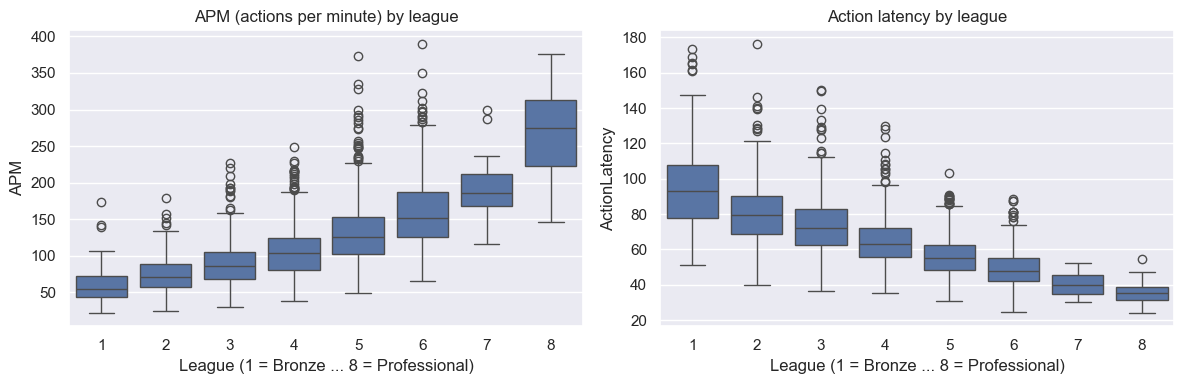

,APM,ActionLatency
LeagueIndex,,
1,54.04,93.33
2,71.68,79.24
3,85.96,72.10
4,103.81,62.77
5,126.01,54.99
6,152.19,47.96
7,185.34,39.73
8,274.34,35.41


In [12]:
# How do speed (APM) and reaction time (ActionLatency) change with league?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="LeagueIndex", y="APM", ax=axes[0])
axes[0].set_title("APM (actions per minute) by league")
sns.boxplot(data=df, x="LeagueIndex", y="ActionLatency", ax=axes[1])
axes[1].set_title("Action latency by league")
for ax in axes:
    ax.set_xlabel("League (1 = Bronze ... 8 = Professional)")
plt.tight_layout()
plt.savefig(FIG_DIR / "skillcraft_apm_latency_by_league.png", dpi=150)
plt.show()

df.groupby("LeagueIndex")[["APM", "ActionLatency"]].median().round(2)

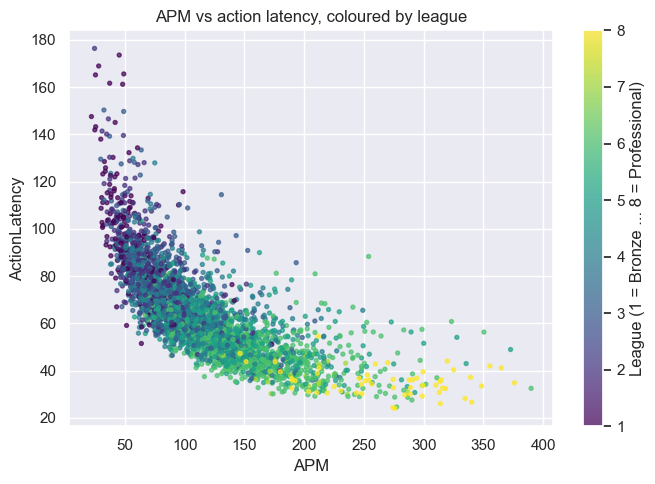

In [13]:
# Scatter plot of the two strongest features, coloured by league.
plt.figure(figsize=(7, 5))
points = plt.scatter(df["APM"].values, df["ActionLatency"].values, c=df["LeagueIndex"].values, cmap="viridis", s=8, alpha=0.7)
plt.colorbar(points, label="League (1 = Bronze ... 8 = Professional)")
plt.xlabel("APM")
plt.ylabel("ActionLatency")
plt.title("APM vs action latency, coloured by league")
plt.tight_layout()
plt.savefig(FIG_DIR / "skillcraft_apm_latency_scatter.png", dpi=150)
plt.show()

In [14]:
# Correlation of each feature with the (ordered) league.
# Descriptive only: it uses ALL players, so it is NOT used for feature selection (Section 3 uses training data only).
corr_with_league = df.drop(columns=drop_cols).corr()["LeagueIndex"].drop("LeagueIndex")
corr_with_league.sort_values(key=abs, ascending=False).round(3)

ActionLatency          -0.674
APM                     0.662
NumberOfPACs            0.612
GapBetweenPACs         -0.553
AssignToHotkeys         0.531
SelectByHotkeys         0.491
UniqueHotkeys           0.351
MinimapAttacks          0.313
WorkersMade             0.296
MinimapRightClicks      0.233
TotalMapExplored        0.221
ComplexUnitsMade        0.149
ComplexAbilitiesUsed    0.146
ActionsInPAC            0.143
UniqueUnitsMade         0.134
Name: LeagueIndex, dtype: float64

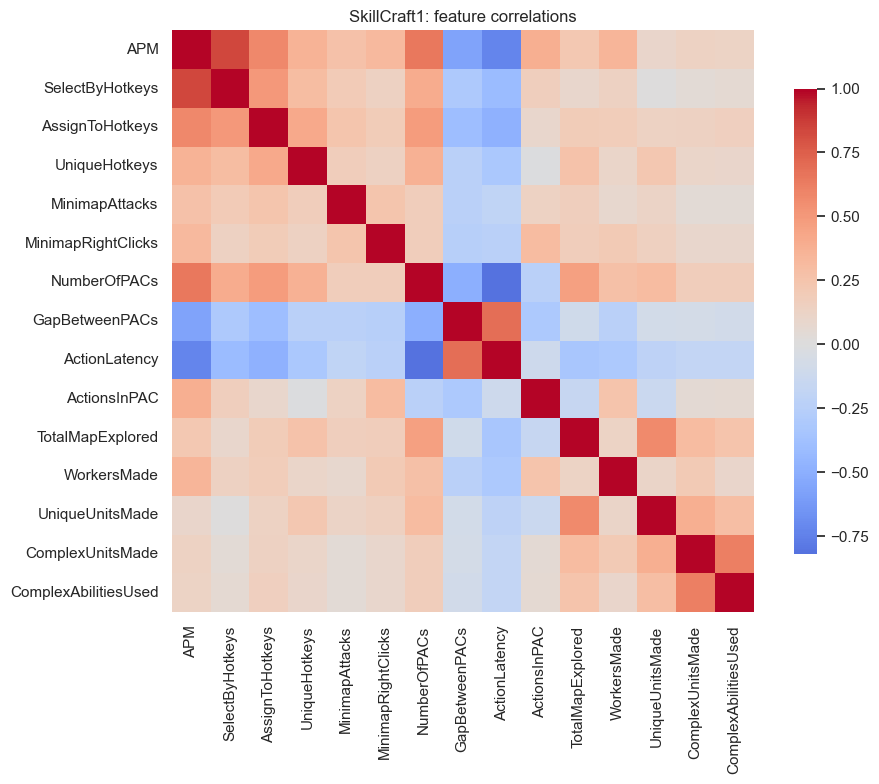

Most correlated feature pairs:
APM             SelectByHotkeys    0.841
NumberOfPACs    ActionLatency      0.820
APM             ActionLatency      0.722
GapBetweenPACs  ActionLatency      0.689
APM             NumberOfPACs       0.651
dtype: float64


In [15]:
# Correlation matrix between the features.
plt.figure(figsize=(10, 8))
corr = X.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("SkillCraft1: feature correlations")
plt.tight_layout()
plt.savefig(FIG_DIR / "skillcraft_correlation_heatmap.png", dpi=150)
plt.show()

# The most strongly correlated feature pairs (features that measure nearly the same thing).
pairs = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("Most correlated feature pairs:")
print(pairs.head(5).round(3))

### 2.5 Train/test split

In [16]:
from sklearn.model_selection import train_test_split

# 80% training, 20% test. stratify=y keeps the same league proportions in both sets.
# From here on, all feature selection and tuning uses the TRAINING set only;
# the test set is used once, in Section 12.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())
print("\nTest class distribution:")
print(y_test.value_counts().sort_index())

Training feature shape: (2716, 15)
Test feature shape: (679, 15)

Training class distribution:
LeagueIndex
1    134
2    277
3    442
4    649
5    645
6    497
7     28
8     44
Name: count, dtype: int64

Test class distribution:
LeagueIndex
1     33
2     70
3    111
4    162
5    161
6    124
7      7
8     11
Name: count, dtype: int64


### 2.6 Imports and evaluation helpers for the models
Everything needed from scikit-learn for Sections 3–12 is imported here, once.
* `cv_scores`: **10-fold stratified cross-validation on the training data**. It reports mean training accuracy, CV accuracy, macro precision, recall, F1, macro ROC-AUC, and the **train–CV gap** (a big gap = overfitting).
* `evaluate_model`: all the evaluation metrics for one set of predictions. With 8 leagues, each league is treated **one-vs-rest** ("Gold" vs "not Gold"). TP, FP, TN and FN are added up over the 8 leagues; sensitivity, specificity and precision are **averaged over the leagues** (macro), so the 35 GrandMasters count as much as the 811 Platinum players.

Scalers always sit **inside a Pipeline**. That way they are re-fitted on the training part of every fold and never see the held-out fold.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV  # CV tools
from sklearn.pipeline import Pipeline                             # chains steps, re-fitted inside every fold
from sklearn.compose import ColumnTransformer                     # keeps (and scales) only some columns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, KBinsDiscretizer, FunctionTransformer  # scaling and binning
from sklearn.decomposition import PCA                             # principal component analysis
from sklearn.dummy import DummyClassifier                         # the "always guess the most common league" baseline
from sklearn.neighbors import KNeighborsClassifier                # k-nearest neighbours
from sklearn.tree import DecisionTreeClassifier, plot_tree        # decision tree and a function to draw it
from sklearn.ensemble import RandomForestClassifier               # random forest
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDClassifier, Perceptron  # linear models
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, CategoricalNB  # Naive Bayes variants
from sklearn.neural_network import MLPClassifier                  # multi-layer perceptron
from sklearn.cluster import KMeans                                # k-means clustering
from sklearn.mixture import GaussianMixture                       # a second clustering method
from sklearn.base import clone                                    # an untrained copy of a model
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,   # basic metrics
                             confusion_matrix, multilabel_confusion_matrix,              # confusion matrices
                             roc_auc_score, roc_curve, mean_squared_error, r2_score,     # ROC and regression errors
                             classification_report, silhouette_score,                    # per-class report, clustering
                             adjusted_rand_score, normalized_mutual_info_score)          # clustering vs the real leagues
warnings.filterwarnings("ignore", category=UserWarning)           # hide KBinsDiscretizer notices (empty bins)
warnings.filterwarnings("ignore", category=FutureWarning)         # hide library deprecation notices

SEED = 42                                                         # the same random seed everywhere
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)  # the same 10 stratified folds for every experiment
LEAGUES = list(range(1, 9))                                       # the league numbers 1-8
model_results = {}                                                # stores one row of metrics per evaluated model


def cv_scores(model, X, y, name, auc=True):  # define the helper function cv_scores()
    """10-fold stratified cross-validation on the TRAINING data. Returns the average scores as one table row."""
    scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]   # metrics to record
    if auc:                                                                  # ROC-AUC needs predicted probabilities
        scoring.append("roc_auc_ovr")                                        # one-vs-rest AUC, averaged over leagues
    scores = cross_validate(model, X, y, cv=CV10, n_jobs=-1, return_train_score=True, scoring=scoring)  # train and score 10 times
    return {"model": name,                                                   # name shown in the table
            "train_acc": scores["train_accuracy"].mean(),                    # accuracy on the data the model learned from
            "cv_acc": scores["test_accuracy"].mean(),                        # accuracy on the held-out fold
            "cv_acc_sd": scores["test_accuracy"].std(),                      # how much the 10 folds disagree
            "precision": scores["test_precision_macro"].mean(),              # macro precision
            "recall": scores["test_recall_macro"].mean(),                    # macro recall
            "macro_f1": scores["test_f1_macro"].mean(),                      # macro F1 (our main metric)
            "macro_f1_sd": scores["test_f1_macro"].std(),                    # spread of macro F1 over the folds
            "roc_auc": scores["test_roc_auc_ovr"].mean() if auc else np.nan, # macro one-vs-rest ROC-AUC
            "gap": scores["train_accuracy"].mean() - scores["test_accuracy"].mean()}  # big gap = overfitting


def evaluate_model(model_name, y_true, y_pred, y_prob=None, show=True):  # define the helper function evaluate_model()
    """All evaluation metrics. Each league is scored one-vs-rest; rates are averaged over the 8 leagues (macro)."""
    m = multilabel_confusion_matrix(y_true, y_pred, labels=LEAGUES)  # one 2x2 confusion matrix per league
    tn, fp, fn, tp = m[:, 0, 0], m[:, 0, 1], m[:, 1, 0], m[:, 1, 1]  # the four counts for every league
    row = {"accuracy": accuracy_score(y_true, y_pred),               # share of players put in the right league
           "TP": tp.sum(), "FP": fp.sum(), "TN": tn.sum(), "FN": fn.sum(),  # counts added up over the 8 leagues
           "sensitivity": np.mean(tp / (tp + fn)),                   # TP rate = recall, averaged over leagues
           "specificity": np.mean(tn / (tn + fp)),                   # TN rate, averaged over leagues
           "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),  # macro precision
           "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),        # macro recall
           "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),          # macro F1
           "roc_auc": roc_auc_score(y_true, y_prob, multi_class="ovr") if y_prob is not None else np.nan}  # needs probabilities
    model_results[model_name] = row                                  # keep it for the comparison tables
    if show:                                                         # print a short summary
        print(f"{model_name}: accuracy {row['accuracy']:.4f} | macro F1 {row['macro_f1']:.4f} | ROC-AUC {row['roc_auc']:.4f}")  # summary line
    return row                                                       # also return it, so it can go straight into a table


METRIC_COLUMNS = ["accuracy", "TP", "FP", "TN", "FN", "sensitivity", "specificity", "precision", "recall", "macro_f1", "roc_auc"]  # metric table columns
FEATURES = X_train.columns.tolist()                               # the 15 gameplay feature names
print("Evaluation helpers ready.")                                # confirm the cell ran

Evaluation helpers ready.


## 3. Feature analysis and selection
### 3.1 Most correlated features, overall and per league (training data only)
For each league, the target is turned into a **one-vs-rest 0/1 label** (for example "Master or not"), and every feature is correlated with that label. Three data sets with fewer and fewer features are formed: **Data set 1 / 2 / 3 = the top 2 / 5 / 10 features of every league** (combined, so a feature that is in the top list of several leagues is counted once).

All features                   15 features: ['APM', 'SelectByHotkeys', 'AssignToHotkeys', 'UniqueHotkeys', 'MinimapAttacks', 'MinimapRightClicks', 'NumberOfPACs', 'GapBetweenPACs', 'ActionLatency', 'ActionsInPAC', 'TotalMapExplored', 'WorkersMade', 'UniqueUnitsMade', 'ComplexUnitsMade', 'ComplexAbilitiesUsed']
Data set 1 (top 2 per class)    6 features: ['ActionLatency', 'APM', 'NumberOfPACs', 'GapBetweenPACs', 'AssignToHotkeys', 'SelectByHotkeys']
Data set 2 (top 5 per class)    9 features: ['ActionLatency', 'APM', 'NumberOfPACs', 'GapBetweenPACs', 'AssignToHotkeys', 'SelectByHotkeys', 'UniqueHotkeys', 'MinimapAttacks', 'WorkersMade']
Data set 3 (top 10 per class)  13 features: ['ActionLatency', 'APM', 'NumberOfPACs', 'GapBetweenPACs', 'AssignToHotkeys', 'SelectByHotkeys', 'UniqueHotkeys', 'MinimapAttacks', 'WorkersMade', 'MinimapRightClicks', 'TotalMapExplored', 'ComplexUnitsMade', 'ActionsInPAC']


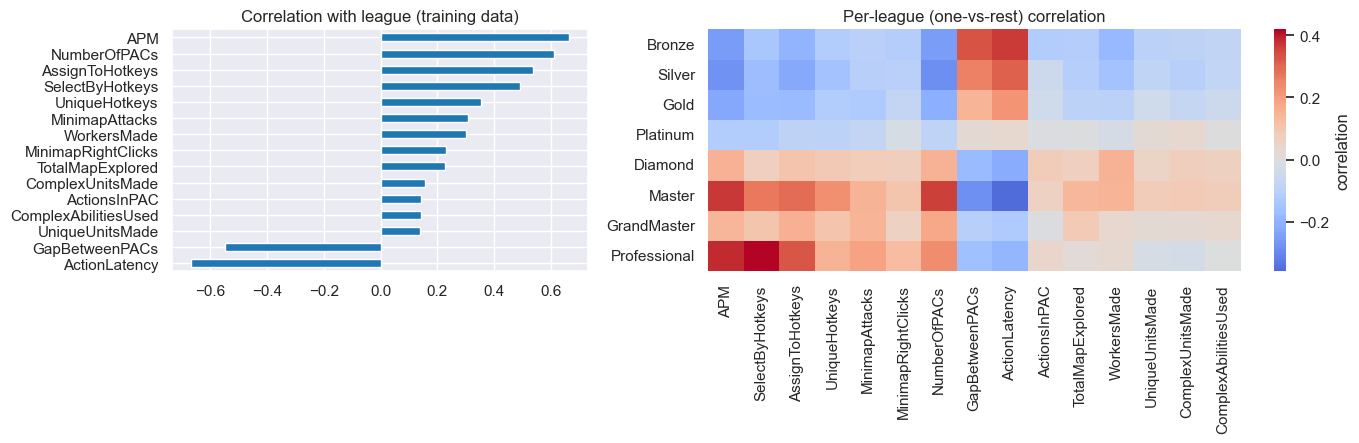

In [18]:
overall_corr = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)  # correlation with the league number 1-8
per_class_corr = pd.DataFrame({league_names[c]: X_train.corrwith((y_train == c).astype(int))  # "this league or not"
                               for c in LEAGUES})                 # one column per league


def top_per_class(k):  # define the helper function top_per_class()
    """The union of the k most correlated features (by absolute value) of every league, in overall order."""
    chosen = set()                                                # features picked so far
    for league in per_class_corr.columns:                         # every league
        chosen.update(per_class_corr[league].abs().nlargest(k).index)  # its k strongest features
    return [f for f in overall_corr.index if f in chosen]         # keep the overall order


feature_sets = {"All features": FEATURES,                         # all 15 features
                "Data set 1 (top 2 per class)": top_per_class(2), # data set 1
                "Data set 2 (top 5 per class)": top_per_class(5), # data set 2
                "Data set 3 (top 10 per class)": top_per_class(10)}  # data set 3
for name, cols in feature_sets.items():                           # show what is in every set
    print(f"{name:30s} {len(cols):2d} features: {cols}")          # name, size and features

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})  # two plots side by side
overall_corr.sort_values().plot(kind="barh", ax=axes[0], color="tab:blue")  # overall correlation per feature
axes[0].set_title("Correlation with league (training data)")      # plot title
sns.heatmap(per_class_corr.T, cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"label": "correlation"})  # leagues x features
axes[1].set_title("Per-league (one-vs-rest) correlation")         # plot title
plt.tight_layout()                                                # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_feature_correlation.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                        # display the figure

### 3.2 Do fewer features still work? k-NN and Logistic Regression on each data set
Each data set is scored with two fixed classifiers using 10-fold out-of-fold predictions and all the evaluation metrics. **PCA** (keeping the components that explain 90% of the variance) is added as a feature *transformation* to compare with feature *selection*. Scaling and PCA are inside the pipeline, so they are re-fitted in every fold.

In [19]:
classifiers = {"k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),   # fixed settings
               "Logistic Regression": LogisticRegression(max_iter=2000)}  # fixed settings
fs_rows = []                                                        # one row per (data set, classifier)
for set_name, cols in feature_sets.items():                         # every data set
    for clf_name, clf in classifiers.items():                       # both classifiers
        pipe = Pipeline([("scale", StandardScaler()), ("clf", clf)])  # scale, then classify
        prob = cross_val_predict(pipe, X_train[cols], y_train, cv=CV10, method="predict_proba", n_jobs=-1)  # 10-fold out-of-fold
        row = evaluate_model(f"{clf_name} | {set_name}", y_train, np.array(LEAGUES)[prob.argmax(axis=1)], prob, show=False)  # metrics
        fs_rows.append({"feature_set": set_name, "n_features": len(cols), "model": clf_name, **row})  # save the row
n_pca = PCA(n_components=0.90).fit(StandardScaler().fit_transform(X_train)).n_components_  # number of components for 90%
for clf_name, clf in classifiers.items():                           # both classifiers on PCA
    pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA(n_components=0.90, random_state=SEED)), ("clf", clf)])  # scale, PCA, classify
    prob = cross_val_predict(pipe, X_train, y_train, cv=CV10, method="predict_proba", n_jobs=-1)  # 10-fold out-of-fold
    row = evaluate_model(f"{clf_name} | PCA", y_train, np.array(LEAGUES)[prob.argmax(axis=1)], prob, show=False)  # metrics
    fs_rows.append({"feature_set": "PCA (90% variance)", "n_features": n_pca, "model": clf_name, **row})  # save the row

fs_table = pd.DataFrame(fs_rows)                                    # all results as one table
full = fs_table[fs_table["feature_set"] == "All features"].set_index("model")["macro_f1"]  # score with all features
fs_table["retained_vs_all"] = fs_table["macro_f1"] / fs_table["model"].map(full)  # share of the full score that is kept
fs_table.assign(dataset="SkillCraft").to_csv(RESULTS_DIR / "featuresets_SkillCraft.csv", index=False)  # for the cross-dataset summary
print(f"PCA keeps {n_pca} components for 90% of the variance")      # PCA size
fs_table[["feature_set", "n_features", "model"] + METRIC_COLUMNS + ["retained_vs_all"]].round(4)  # the results table

PCA keeps 10 components for 90% of the variance


,feature_set,n_features,model,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,macro_f1,roc_auc,retained_vs_all
0,All features,15,k-NN (k=5),0.3369,915,1801,17211,1801,0.2969,0.8975,0.3267,0.2969,0.3061,0.7164,1.0000
1,All features,15,Logistic Regression,0.4010,1089,1627,17385,1627,0.3555,0.9059,0.3891,0.3555,0.3669,0.8311,1.0000
2,Data set 1 (top 2 per class),6,k-NN (k=5),0.3152,856,1860,17152,1860,0.2939,0.8944,0.3098,0.2939,0.2990,0.6914,0.9770
3,Data set 1 (top 2 per class),6,Logistic Regression,0.3903,1060,1656,17356,1656,0.3441,0.9039,0.5103,0.3441,0.3615,0.8281,0.9852
4,Data set 2 (top 5 per class),9,k-NN (k=5),0.3277,890,1826,17186,1826,0.3026,0.8962,0.3239,0.3026,0.3094,0.7145,1.0110
5,Data set 2 (top 5 per class),9,Logistic Regression,0.3999,1086,1630,17382,1630,0.3539,0.9057,0.3851,0.3539,0.3640,0.8343,0.9920
6,Data set 3 (top 10 per class),13,k-NN (k=5),0.3273,889,1827,17185,1827,0.2874,0.8959,0.3175,0.2874,0.2975,0.7166,0.9721
7,Data set 3 (top 10 per class),13,Logistic Regression,0.4032,1095,1621,17391,1621,0.3593,0.9063,0.3903,0.3593,0.3695,0.8325,1.0070
8,PCA (90% variance),10,k-NN (k=5),0.3225,876,1840,17172,1840,0.2925,0.8952,0.3231,0.2925,0.3027,0.7036,0.9891
9,PCA (90% variance),10,Logistic Regression,0.3940,1070,1646,17366,1646,0.3568,0.9047,0.4289,0.3568,0.3722,0.8310,1.0144


In [20]:
knn_rows_fs = fs_table[(fs_table["model"] == "k-NN (k=5)") & (fs_table["feature_set"] != "PCA (90% variance)")]  # k-NN, selection only
best_set = knn_rows_fs.loc[knn_rows_fs["macro_f1"].idxmax(), "feature_set"]  # best feature set for k-NN
KNN_COLS = feature_sets[best_set]                                   # its features, used in Sections 4 and 5
print("Best feature set for k-NN:", best_set, "->", KNN_COLS)        # result

Best feature set for k-NN: Data set 2 (top 5 per class) -> ['ActionLatency', 'APM', 'NumberOfPACs', 'GapBetweenPACs', 'AssignToHotkeys', 'SelectByHotkeys', 'UniqueHotkeys', 'MinimapAttacks', 'WorkersMade']


**What we found.** The same few "speed" features come out on top for almost every league: `ActionLatency`, `APM`, `NumberOfPACs` and `GapBetweenPACs`. So the small data sets are not much smaller than the full one in what they contain. Data set 1 (only 6 features) keeps **98.5%** of the Logistic Regression macro F1 with all 15 features (0.362 vs 0.367), and **97.7%** for k-NN. For k-NN the best set is Data set 2 (9 features, macro F1 0.309 vs 0.306 with all features). Dropping the 6 weakest features removes noise from the distance, which is why k-NN is slightly better with fewer features. PCA with 10 components gives about the same result as all features (LR 0.372). **Conclusion:** on SkillCraft most of the information is in a handful of correlated speed features, so feature selection costs almost nothing. We keep Data set 2 for k-NN and all features for the other models.

## 4. Model testing: hold-out split vs cross-validation, and choice of metric
A simple train/test split is compared with 10-fold cross-validation. The same k-NN is scored on **five different 80/20 hold-out splits** of the training data and with **10-fold CV**. The **majority baseline** ("always guess Platinum") is scored with all the metrics as well, to see which metric is misleading on imbalanced leagues.

In [21]:
def knn_pipeline(k):  # define the helper function knn_pipeline()
    """k-NN on the chosen features: keep and scale only KNN_COLS, then classify."""
    keep_and_scale = ColumnTransformer([("scale", StandardScaler(), KNN_COLS)])  # other columns are dropped
    return Pipeline([("prep", keep_and_scale), ("clf", KNeighborsClassifier(n_neighbors=k))])  # the full model


holdout_rows = []                                                   # one row per hold-out split
for split_seed in range(5):                                         # five different random splits
    X_a, X_b, y_a, y_b = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=split_seed)  # 80/20
    pred = knn_pipeline(5).fit(X_a, y_a).predict(X_b)               # train on 80%, predict the other 20%
    holdout_rows.append({"split seed": split_seed,                  # which split
                         "accuracy": accuracy_score(y_b, pred),     # accuracy
                         "macro_f1": f1_score(y_b, pred, average="macro")})  # macro F1
holdout = pd.DataFrame(holdout_rows)                                # as a table
print(holdout.round(4).to_string(index=False))                      # show the five results

knn_cv = cv_scores(knn_pipeline(5), X_train, y_train, "k-NN (k=5), 10-fold CV")  # 10-fold CV
print(f"\nHold-out macro F1 range: {holdout['macro_f1'].min():.4f} - {holdout['macro_f1'].max():.4f} (sd {holdout['macro_f1'].std():.4f})")  # spread
print(f"10-fold CV macro F1: {knn_cv['macro_f1']:.4f} (sd over folds {knn_cv['macro_f1_sd']:.4f})")  # the CV estimate

 split seed  accuracy  macro_f1
          0    0.3456    0.3358
          1    0.3382    0.3349
          2    0.3290    0.3065
          3    0.3107    0.3061
          4    0.3456    0.2997



Hold-out macro F1 range: 0.2997 - 0.3358 (sd 0.0173)
10-fold CV macro F1: 0.3058 (sd over folds 0.0278)


In [22]:
cv_store = {"Majority baseline": cv_scores(DummyClassifier(strategy="most_frequent"), X_train, y_train, "Majority baseline")}  # CV results of the final models
base_prob = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_train, y_train, cv=CV10, method="predict_proba")  # always the same
base_row = evaluate_model("Majority baseline (always Platinum)", y_train, np.array(LEAGUES)[base_prob.argmax(axis=1)], base_prob)  # its metrics
knn_prob = cross_val_predict(knn_pipeline(5), X_train, y_train, cv=CV10, method="predict_proba", n_jobs=-1)  # k-NN, out-of-fold
knn_row = evaluate_model("k-NN (k=5)", y_train, np.array(LEAGUES)[knn_prob.argmax(axis=1)], knn_prob)  # its metrics
pd.DataFrame([base_row, knn_row], index=["Majority baseline", "k-NN (k=5)"])[METRIC_COLUMNS].round(4)  # side by side

Majority baseline (always Platinum): accuracy 0.2390 | macro F1 0.0482 | ROC-AUC 0.5000
k-NN (k=5): accuracy 0.3277 | macro F1 0.3094 | ROC-AUC 0.7145


,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,macro_f1,roc_auc
Majority baseline,0.2390,649,2067,16945,2067,0.1250,0.8750,0.0299,0.1250,0.0482,0.5000
k-NN (k=5),0.3277,890,1826,17186,1826,0.3026,0.8962,0.3239,0.3026,0.3094,0.7145


**Hold-out vs CV.** The five 80/20 hold-out splits give k-NN macro F1 values from **0.300 to 0.336**, so a single split could make the same model look 3.6 points better or worse just by luck. 10-fold CV uses every training player for testing exactly once and gives one more stable estimate (0.306, sd 0.028 over the folds). All later choices are therefore made with 10-fold CV.

**Choice of metric.** The majority baseline ("always Platinum") already reaches **23.9% accuracy** and a specificity of 0.875, although it has learned nothing. Its macro F1 is only **0.048**, because it gets 7 of the 8 leagues completely wrong. This is why macro F1 is our main metric on SkillCraft: accuracy and specificity look good even for a useless model when the classes are imbalanced.

## 5. k-Nearest Neighbours: choosing k
Small k follows the training data very closely (risk of overfitting); large k averages over many neighbours (risk of underfitting). k is chosen by 10-fold CV macro F1.

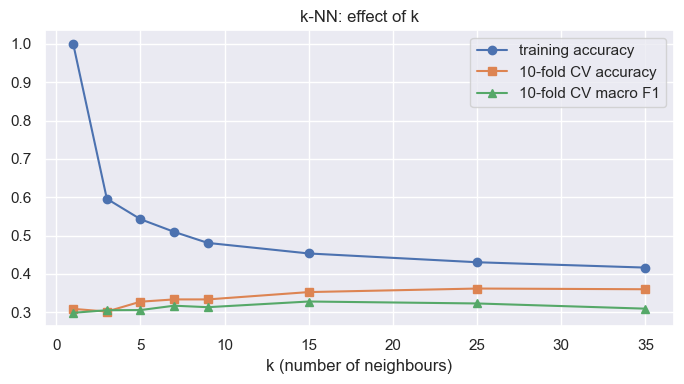

Best k by CV macro F1: 15


,model,train_acc,cv_acc,precision,recall,macro_f1,roc_auc,gap
0,k=1,1.0000,0.3089,0.3068,0.3023,0.2987,0.5978,0.6911
1,k=3,0.5959,0.3019,0.3312,0.3101,0.3054,0.6803,0.2940
2,k=5,0.5427,0.3277,0.3276,0.3021,0.3058,0.7136,0.2150
3,k=7,0.5097,0.3336,0.3334,0.3121,0.3172,0.7361,0.1761
4,k=9,0.4809,0.3336,0.3368,0.3048,0.3133,0.7431,0.1473
5,k=15,0.4534,0.3527,0.3579,0.3170,0.3281,0.7652,0.1006
6,k=25,0.4305,0.3619,0.3636,0.3111,0.3230,0.7922,0.0686
7,k=35,0.4165,0.3601,0.3586,0.2943,0.3095,0.8044,0.0565


In [23]:
knn_rows = []                                                       # one row per value of k
for k in [1, 3, 5, 7, 9, 15, 25, 35]:                               # values of k to try
    row = cv_scores(knn_pipeline(k), X_train, y_train, f"k={k}")    # 10-fold CV
    row["k"] = k                                                    # remember k
    knn_rows.append(row)                                            # save the row
knn_table = pd.DataFrame(knn_rows)                                  # results as a table
best_k = int(knn_table.loc[knn_table["macro_f1"].idxmax(), "k"])    # best k by CV macro F1
KNN_FINAL = knn_pipeline(best_k)                                    # the model used in Section 12
cv_store["k-NN"] = knn_table.loc[knn_table["macro_f1"].idxmax()].to_dict()  # keep its CV result

plt.figure(figsize=(7, 4))                                          # one plot
plt.plot(knn_table["k"].values, knn_table["train_acc"].values, "o-", label="training accuracy")  # training accuracy
plt.plot(knn_table["k"].values, knn_table["cv_acc"].values, "s-", label="10-fold CV accuracy")   # CV accuracy
plt.plot(knn_table["k"].values, knn_table["macro_f1"].values, "^-", label="10-fold CV macro F1") # CV macro F1
plt.xlabel("k (number of neighbours)")                              # x-axis label
plt.title("k-NN: effect of k")                                      # plot title
plt.legend()                                                        # legend
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_knn_k.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
print("Best k by CV macro F1:", best_k)                             # result
knn_table[["model", "train_acc", "cv_acc", "precision", "recall", "macro_f1", "roc_auc", "gap"]].round(4)  # the table

**Effect of k.** With k = 1 the model remembers every training player (training accuracy 100%) but CV macro F1 is only 0.299, so it overfits strongly (gap 0.69). As k grows the gap shrinks steadily (0.10 at k = 15, 0.06 at k = 35). The best CV macro F1 is at **k = 15 (0.328)**; beyond that the model starts to average over too many neighbours from other leagues and macro F1 falls again (0.310 at k = 35), even though ROC-AUC keeps rising. Neighbouring leagues overlap a lot in feature space, so k-NN is limited here.

## 6. Decision Trees and Random Forests
### 6.1 Parameters that control the size of the tree (10-fold CV)
A tree grown until every leaf is pure fits the training players perfectly but generalises badly. `max_depth` (how many questions in a row), `min_samples_leaf` (smallest group a leaf may hold) and the split `criterion` (Gini or entropy) limit the tree. Trees do not need scaling, so the raw features are used.

In [24]:
dt_settings = [                                                     # (name, criterion, max_depth, min_samples_leaf)
    ("DT 1: default (grown until pure)", "gini", None, 1),          # no limits
    ("DT 2", "gini", 3, 1),                                         # very shallow
    ("DT 3", "gini", 5, 1),                                         # shallow
    ("DT 4", "gini", 7, 1),                                         # medium depth
    ("DT 5", "gini", 7, 10),                                        # medium depth, leaves of at least 10
    ("DT 6", "entropy", 7, 10),                                     # same with entropy
    ("DT 7", "gini", None, 30),                                     # no depth limit, but big leaves
    ("DT 8", "entropy", 10, 20),                                    # deeper, big leaves, entropy
]  # end of the list
dt_rows = []                                                        # one row per setting
for name, criterion, depth, leaf in dt_settings:                    # every setting
    tree = DecisionTreeClassifier(criterion=criterion, max_depth=depth, min_samples_leaf=leaf, random_state=SEED)  # build the tree
    row = cv_scores(tree, X_train, y_train, name)                   # 10-fold CV
    row.update(criterion=criterion, max_depth=depth, min_samples_leaf=leaf)  # remember the settings
    dt_rows.append(row)                                             # save the row
dt_table = pd.DataFrame(dt_rows)                                    # results as a table
dt_table[["model", "criterion", "max_depth", "min_samples_leaf", "train_acc", "cv_acc", "precision", "recall", "macro_f1", "roc_auc", "gap"]].round(4)  # the table

,model,criterion,max_depth,min_samples_leaf,train_acc,cv_acc,precision,recall,macro_f1,roc_auc,gap
0,DT 1: default (grown until pure),gini,NaN,1,1.0000,0.3155,0.2981,0.2903,0.2903,0.5923,0.6845
1,DT 2,gini,3.0,1,0.3786,0.3501,0.2953,0.3081,0.2857,0.7834,0.0285
2,DT 3,gini,5.0,1,0.4481,0.3593,0.3357,0.2960,0.3005,0.7820,0.0888
3,DT 4,gini,7.0,1,0.5406,0.3480,0.3444,0.2929,0.3034,0.7316,0.1927
4,DT 5,gini,7.0,10,0.5167,0.3549,0.3453,0.3124,0.3157,0.7667,0.1618
5,DT 6,entropy,7.0,10,0.4898,0.3553,0.3469,0.3199,0.3224,0.7492,0.1345
6,DT 7,gini,NaN,30,0.4906,0.3520,0.3339,0.3203,0.3159,0.7826,0.1386
7,DT 8,entropy,10.0,20,0.5010,0.3431,0.3400,0.3044,0.3105,0.7660,0.1578


### 6.2 GridSearchCV over criterion, depth and leaf size, and the depth curve
`GridSearchCV` tries every combination with the same 10 folds and keeps the one with the best macro F1. The depth curve shows training and CV accuracy as the tree gets deeper: this is where overfitting can be seen.

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 40}


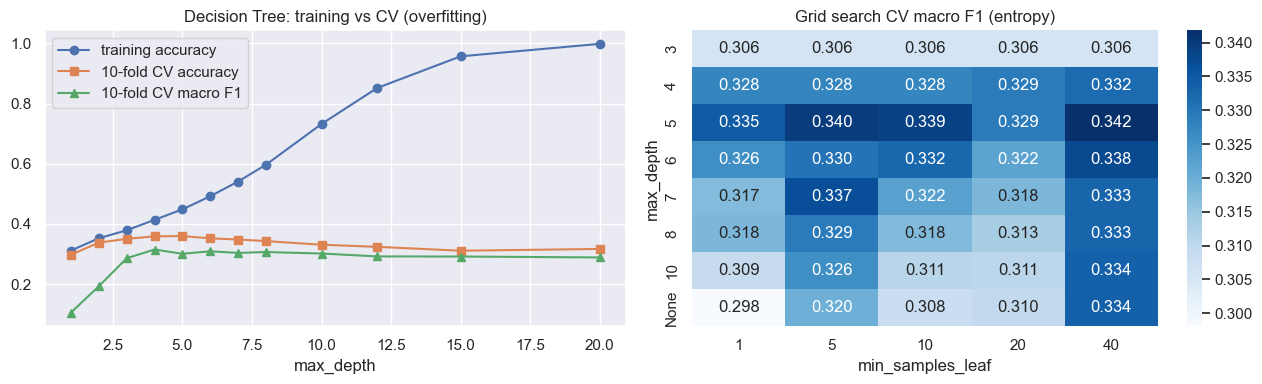

,model,train_acc,cv_acc,macro_f1,roc_auc,gap
0,DT 1: default (grown until pure),1.0000,0.3155,0.2903,0.5923,0.6845
1,Decision Tree (grid search),0.4122,0.3682,0.3418,0.7989,0.0440


In [25]:
param_grid = {"criterion": ["gini", "entropy"],                     # split quality
              "max_depth": [3, 4, 5, 6, 7, 8, 10, None],            # depth
              "min_samples_leaf": [1, 5, 10, 20, 40]}               # leaf size
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid, cv=CV10, scoring="f1_macro", n_jobs=-1)  # the search
dt_grid.fit(X_train, y_train)                                       # run it on the training data
DT_FINAL = dt_grid.best_estimator_                                  # the model used in Section 12
dt_tuned = cv_scores(DT_FINAL, X_train, y_train, "Decision Tree (grid search)")  # its full CV scores
cv_store["Decision Tree"] = dt_tuned                                # keep its CV result
print("Best parameters:", dt_grid.best_params_)                     # chosen settings

depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20]                   # depths for the curve
depth_rows = []                                                     # one row per depth
for d in depths:                                                    # every depth
    row = cv_scores(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train, f"depth {d}")  # 10-fold CV
    depth_rows.append(row)                                          # save the row
depth_table = pd.DataFrame(depth_rows)                              # results as a table

grid = pd.DataFrame(dt_grid.cv_results_)                            # every combination tried
grid = grid[grid["param_criterion"] == dt_grid.best_params_["criterion"]]  # only the best criterion
heat = grid.pivot_table(index=grid["param_max_depth"].astype(str), columns="param_min_samples_leaf", values="mean_test_score")  # depth x leaf
heat = heat.reindex([str(d) for d in param_grid["max_depth"]])          # rows in the order 3, 4, ..., None

fig, axes = plt.subplots(1, 2, figsize=(13, 4))                     # two plots side by side
axes[0].plot(depths, depth_table["train_acc"].values, "o-", label="training accuracy")  # training accuracy
axes[0].plot(depths, depth_table["cv_acc"].values, "s-", label="10-fold CV accuracy")   # CV accuracy
axes[0].plot(depths, depth_table["macro_f1"].values, "^-", label="10-fold CV macro F1") # CV macro F1
axes[0].set_xlabel("max_depth")                                     # x-axis label
axes[0].set_title("Decision Tree: training vs CV (overfitting)")    # plot title
axes[0].legend()                                                    # legend
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", ax=axes[1])  # grid-search results
axes[1].set_xlabel("min_samples_leaf")                              # x-axis label
axes[1].set_ylabel("max_depth")                                     # y-axis label
axes[1].set_title(f"Grid search CV macro F1 ({dt_grid.best_params_['criterion']})")  # plot title
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_tree_tuning.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
pd.DataFrame([dt_rows[0], dt_tuned])[["model", "train_acc", "cv_acc", "macro_f1", "roc_auc", "gap"]].round(4)  # default vs tuned

### 6.3 Random Forest (another tree algorithm, recommended for higher marks)
A Random Forest trains many trees on random samples of the players and features, and lets them vote. `class_weight="balanced"` gives the small leagues more weight while training.

In [26]:
rf_settings = [                                                     # (name, trees, max_depth, min_samples_leaf, class_weight)
    ("RF 1: 100 trees, default", 100, None, 1, None),               # default forest
    ("RF 2: 300 trees, leaf 5", 300, None, 5, None),                # more trees, bigger leaves
    ("RF 3: 300 trees, depth 10", 300, 10, 1, None),                # depth limit
    ("RF 4: 300 trees, leaf 5, balanced", 300, None, 5, "balanced"),  # balanced class weights
]  # end of the list
rf_rows = []                                                        # one row per setting
for name, n_trees, depth, leaf, weight in rf_settings:              # every setting
    forest = RandomForestClassifier(n_estimators=n_trees, max_depth=depth, min_samples_leaf=leaf,  # build the forest
                                    class_weight=weight, random_state=SEED, n_jobs=1)  # one core per forest (CV uses all cores)
    row = cv_scores(forest, X_train, y_train, name)                 # 10-fold CV
    rf_rows.append(row)                                             # save the row
rf_table = pd.DataFrame(rf_rows)                                    # results as a table
best_i = int(rf_table["macro_f1"].idxmax())                         # best forest by CV macro F1
_, n_trees, depth, leaf, weight = rf_settings[best_i]               # its settings
RF_FINAL = RandomForestClassifier(n_estimators=n_trees, max_depth=depth, min_samples_leaf=leaf,  # the model used in Section 12
                                  class_weight=weight, random_state=SEED, n_jobs=1)  # same settings
cv_store["Random Forest"] = rf_table.loc[best_i].to_dict()          # keep its CV result
print("Best forest:", rf_settings[best_i][0])                       # chosen forest
rf_table[["model", "train_acc", "cv_acc", "precision", "recall", "macro_f1", "roc_auc", "gap"]].round(4)  # the table

Best forest: RF 4: 300 trees, leaf 5, balanced


,model,train_acc,cv_acc,precision,recall,macro_f1,roc_auc,gap
0,"RF 1: 100 trees, default",1.0000,0.3722,0.3815,0.3362,0.3486,0.8191,0.6278
1,"RF 2: 300 trees, leaf 5",0.8720,0.3829,0.3999,0.3306,0.3486,0.8319,0.4891
2,"RF 3: 300 trees, depth 10",0.9361,0.3774,0.4017,0.3359,0.3526,0.8295,0.5588
3,"RF 4: 300 trees, leaf 5, balanced",0.8630,0.3686,0.3722,0.3969,0.3728,0.8293,0.4944


### 6.4 What does a tree mean in practice?
A small depth-3 tree, for explanation only: every split is a readable threshold on a gameplay statistic. Next to it are the feature importances of the tuned tree and the forest.

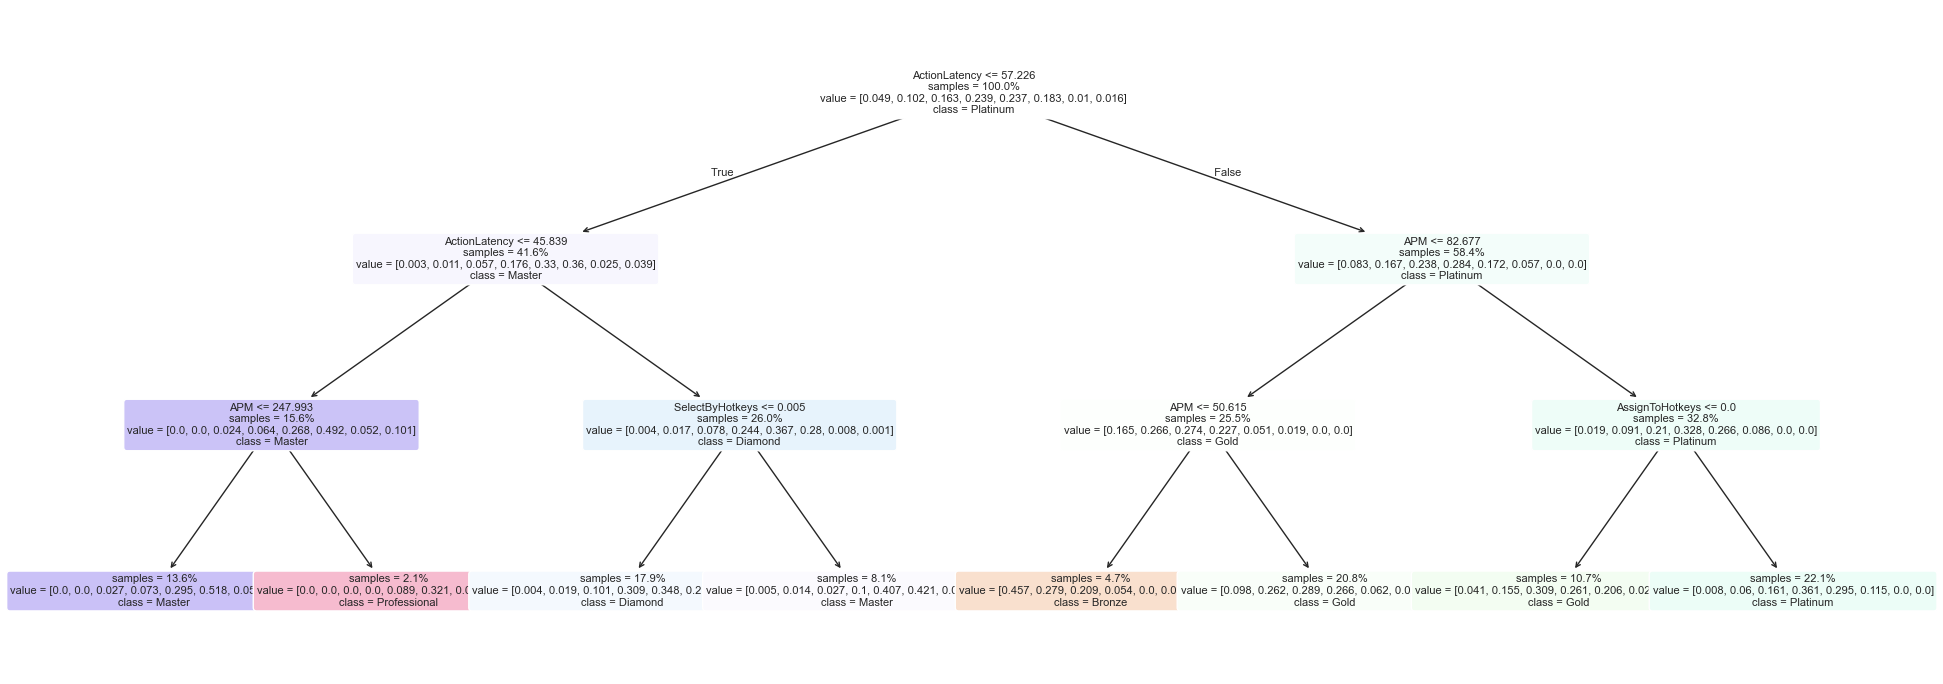

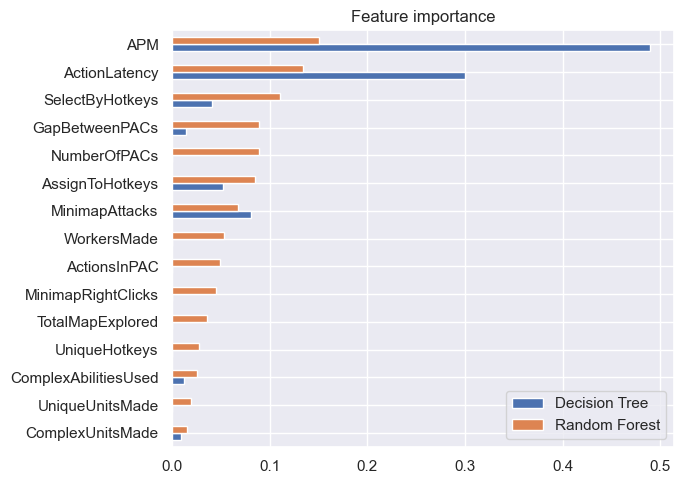

In [27]:
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEED).fit(X_train, y_train)  # small tree
fig, ax = plt.subplots(figsize=(20, 7))                             # a wide figure
plot_tree(small_tree, feature_names=FEATURES, class_names=target_names, filled=True, rounded=True,  # draw the tree
          fontsize=8, impurity=False, proportion=True, ax=ax)        # show class shares in each node
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_small_tree.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure

importance = pd.DataFrame({"Decision Tree": clone(DT_FINAL).fit(X_train, y_train).feature_importances_,   # tuned tree
                           "Random Forest": clone(RF_FINAL).fit(X_train, y_train).feature_importances_},  # best forest
                          index=FEATURES)                           # one row per feature
importance.sort_values("Random Forest").plot(kind="barh", figsize=(7, 5))  # bar chart
plt.title("Feature importance")                                     # plot title
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_tree_importance.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure

**Trees.** The default tree grows until every leaf is pure: 100% training accuracy but only 0.278 CV macro F1, the clearest case of overfitting in this notebook. Limiting the tree helps a lot. The grid search picks **entropy, depth 5, leaves of at least 40 players**, with CV macro F1 **0.341** and a gap of only 0.045. The depth curve shows the usual picture: training accuracy keeps rising with depth, while CV accuracy peaks at a depth of about 5 and then falls.

**Random Forest.** All forests are better than a single tree. The best by macro F1 is RF 4 (`class_weight="balanced"`, 0.365): it gives up some accuracy (0.356 vs 0.380) for a much higher recall on the small leagues (0.417 vs 0.33). The forests still have very large train–CV gaps (0.43–0.63), because every tree is deep, but averaging many trees keeps the CV score up.

**What the tree means (R3).** The depth-3 tree splits first on **`ActionLatency` ≤ 57 ms** (how quickly a player acts after switching screen) and then on `APM`. For example, latency ≤ 46 ms together with APM > 248 leads to Professional, while latency > 57 ms with APM ≤ 51 leads to Bronze. Hotkey use (`SelectByHotkeys`, `AssignToHotkeys`) separates neighbouring leagues lower down. In the tuned tree, APM (0.49) and ActionLatency (0.30) together carry about 80% of the importance. In practice, the tree says that skill shows in *how quickly* a player acts, not in what they build.

*Tree 1 / 2 / 3 (moving 30% and 60% of the training data into the test set) are run for every model together in Section 12.2.*

## 7. Linear and Logistic Regression
### 7.1 Linear regression: is the data linearly separable?
Two versions:
* **(a) ordinal:** one regression on the league number 1–8 (the league is ordered, so this makes sense here), rounded to the nearest league.
* **(b) a one-vs-rest linear classifier:** one regression per league on a 0/1 target ("this league or not"), predicting the league with the largest output.

If the leagues were **linearly separable**, (b) would reach (close to) 100% **training** accuracy. As a reference, always predicting the mean league gives an MSE equal to the variance of the league numbers.

In [28]:
scaler = StandardScaler().fit(X_train)                              # learn mean and sd from the training data only
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)  # scaled versions
Y_train = pd.get_dummies(y_train).astype(float).to_numpy()          # one 0/1 column per league (training)
Y_test = pd.get_dummies(y_test).astype(float).to_numpy()            # one 0/1 column per league (test)
ordinal = LinearRegression().fit(Xs_train, y_train)                 # (a) regression on 1-8
onehot = LinearRegression().fit(Xs_train, Y_train)                  # (b) one regression per league

lin_rows = []                                                       # one row for training, one for test
for set_name, Xs, y_set, Y_set in [("training", Xs_train, y_train, Y_train), ("test", Xs_test, y_test, Y_test)]:  # both sets
    out = ordinal.predict(Xs)                                       # (a) raw output
    league_guess = np.clip(np.rint(out), 1, 8)                      # rounded to a league 1-8
    lin_rows.append({"set": set_name,                               # which set
                     "ordinal MSE": mean_squared_error(y_set, out), # mean squared error of (a)
                     "ordinal R2": r2_score(y_set, out),            # share of variance explained
                     "ordinal exact league": accuracy_score(y_set, league_guess),  # rounded output = true league
                     "ordinal within 1 league": np.mean(np.abs(league_guess - y_set) <= 1),  # off by at most one league
                     "one-hot MSE": mean_squared_error(Y_set, onehot.predict(Xs)),  # mean squared error of (b)
                     "linear classifier accuracy": accuracy_score(y_set, np.array(LEAGUES)[onehot.predict(Xs).argmax(axis=1)])})  # (b) as a classifier
print(f"Constant-guess MSE (always the mean league): {y_train.var(ddof=0):.4f}")  # the reference MSE
pd.DataFrame(lin_rows).round(4)                                     # the results

Constant-guess MSE (always the mean league): 2.3021


,set,ordinal MSE,ordinal R2,ordinal exact league,ordinal within 1 league,one-hot MSE,linear classifier accuracy
0,training,0.9914,0.5694,0.3855,0.8686,0.0922,0.3711
1,test,0.9484,0.5876,0.4094,0.8675,0.0916,0.3976


### 7.2 Logistic Regression: regularisation strength C (10-fold CV)
Small `C` = the weights are kept small (a simpler model); large `C` = the model is freer to fit the training data. The training error is shown next to the CV error.

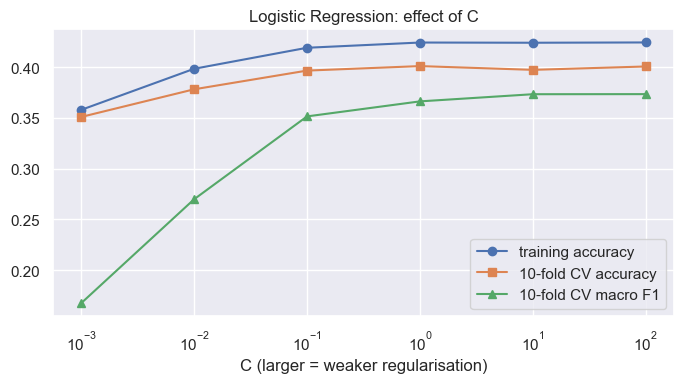

Best C: 100.0


,C,train_acc,training_error,cv_acc,precision,recall,macro_f1,roc_auc,gap
0,0.001,0.3578,0.6422,0.3509,0.1879,0.1952,0.1675,0.7890,0.0070
1,0.010,0.3983,0.6017,0.3781,0.3719,0.2589,0.2698,0.8233,0.0202
2,0.100,0.4190,0.5810,0.3965,0.4048,0.3352,0.3514,0.8309,0.0225
3,1.000,0.4242,0.5758,0.4009,0.4060,0.3544,0.3662,0.8322,0.0232
4,10.000,0.4239,0.5761,0.3973,0.4107,0.3635,0.3733,0.8320,0.0267
5,100.000,0.4242,0.5758,0.4006,0.4073,0.3656,0.3733,0.8321,0.0237


In [29]:
lr_rows = []                                                        # one row per value of C
for C in [0.001, 0.01, 0.1, 1, 10, 100]:                            # from strong to weak regularisation
    model = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=C, max_iter=2000))])  # scale, then classify
    row = cv_scores(model, X_train, y_train, f"C={C}")              # 10-fold CV
    row["C"] = C                                                    # remember C
    row["training_error"] = 1 - row["train_acc"]                    # training error = 1 - training accuracy
    lr_rows.append(row)                                             # save the row
lr_table = pd.DataFrame(lr_rows)                                    # results as a table
best_lr = lr_table.loc[lr_table["macro_f1"].idxmax()]               # best C by CV macro F1
LR_FINAL = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(C=float(best_lr["C"]), max_iter=2000))])  # used in Section 12
cv_store["Logistic Regression"] = best_lr.to_dict()                 # keep its CV result

plt.figure(figsize=(7, 4))                                          # one plot
plt.semilogx(lr_table["C"].values, lr_table["train_acc"].values, "o-", label="training accuracy")  # log scale for C
plt.semilogx(lr_table["C"].values, lr_table["cv_acc"].values, "s-", label="10-fold CV accuracy")   # CV accuracy
plt.semilogx(lr_table["C"].values, lr_table["macro_f1"].values, "^-", label="10-fold CV macro F1") # CV macro F1
plt.xlabel("C (larger = weaker regularisation)")                    # x-axis label
plt.title("Logistic Regression: effect of C")                       # plot title
plt.legend()                                                        # legend
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_logreg_C.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
print("Best C:", best_lr["C"])                                      # chosen C
lr_table[["C", "train_acc", "training_error", "cv_acc", "precision", "recall", "macro_f1", "roc_auc", "gap"]].round(4)  # the table

### 7.3 Learning rate, batch size and number of epochs (gradient descent)
`SGDClassifier(loss="log_loss")` is logistic regression trained **step by step** with mini-batch gradient descent, so the learning parameters can be changed directly: the **learning rate** (step size), the **batch size** (players per step) and the number of **epochs** (passes over the data). It is scored on a validation split taken from the training data; the test set is not used.

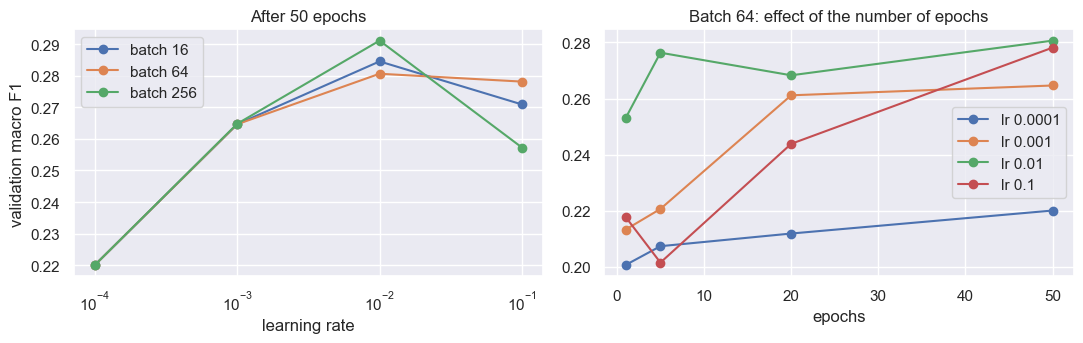

epochs                        1       5       20      50
learning_rate batch_size                                
0.0001        16          0.1994  0.2073  0.2119  0.2201
              64          0.2006  0.2073  0.2119  0.2201
              256         0.1994  0.2073  0.2119  0.2201
0.0010        16          0.2132  0.2206  0.2603  0.2646
              64          0.2132  0.2206  0.2612  0.2646
              256         0.2131  0.2218  0.2614  0.2648
0.0100        16          0.2646  0.2420  0.2636  0.2846
              64          0.2530  0.2763  0.2683  0.2807
              256         0.2545  0.2636  0.2576  0.2911
0.1000        16          0.2132  0.1842  0.2123  0.2709
              64          0.2178  0.2015  0.2438  0.2782
              256         0.2182  0.2256  0.2769  0.2573

In [30]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)  # 80/20 of training
fit_scaler = StandardScaler().fit(X_fit)                            # scaler learned on the 80% part only
X_fit_s, X_val_s = fit_scaler.transform(X_fit), fit_scaler.transform(X_val)  # scaled versions
y_fit_np = y_fit.to_numpy()                                         # NumPy array for indexing

sgd_rows = []                                                       # one row per (learning rate, batch size, epochs)
for lr_value in [0.0001, 0.001, 0.01, 0.1]:                         # learning rates to try
    for batch in [16, 64, 256]:                                     # batch sizes to try
        sgd = SGDClassifier(loss="log_loss", learning_rate="constant", eta0=lr_value, random_state=SEED)  # logistic regression by SGD
        rng = np.random.default_rng(SEED)                           # random order of the players in every epoch
        for epoch in range(1, 51):                                  # up to 50 passes over the data
            order = rng.permutation(len(y_fit_np))                  # shuffle the players
            for start in range(0, len(order), batch):               # go through them one batch at a time
                idx = order[start:start + batch]                    # the players in this batch
                sgd.partial_fit(X_fit_s[idx], y_fit_np[idx], classes=LEAGUES)  # one gradient step
            if epoch in (1, 5, 20, 50):                             # record the result after 1, 5, 20 and 50 epochs
                sgd_rows.append({"learning_rate": lr_value, "batch_size": batch, "epochs": epoch,  # the settings
                                 "train_acc": accuracy_score(y_fit, sgd.predict(X_fit_s)),        # training accuracy
                                 "val_macro_f1": f1_score(y_val, sgd.predict(X_val_s), average="macro")})  # validation macro F1
sgd_table = pd.DataFrame(sgd_rows)                                  # results as a table

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))                   # two plots side by side
for batch, part in sgd_table[sgd_table["epochs"] == 50].groupby("batch_size"):   # after 50 epochs, one line per batch size
    axes[0].semilogx(part["learning_rate"].values, part["val_macro_f1"].values, "o-", label=f"batch {batch}")  # F1 vs learning rate
axes[0].set_xlabel("learning rate")                                 # x-axis label
axes[0].set_ylabel("validation macro F1")                           # y-axis label
axes[0].set_title("After 50 epochs")                                # plot title
axes[0].legend()                                                    # legend
for lr_value, part in sgd_table[sgd_table["batch_size"] == 64].groupby("learning_rate"):  # batch 64, one line per learning rate
    axes[1].plot(part["epochs"].values, part["val_macro_f1"].values, "o-", label=f"lr {lr_value}")  # F1 vs epochs
axes[1].set_xlabel("epochs")                                        # x-axis label
axes[1].set_title("Batch 64: effect of the number of epochs")       # plot title
axes[1].legend()                                                    # legend
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_sgd.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
sgd_table.pivot_table(index=["learning_rate", "batch_size"], columns="epochs", values="val_macro_f1").round(4)  # rows = settings, columns = epochs

**Linear regression.** Treating the league as a number 1–8 works quite well: MSE **0.95** on the test set vs **2.30** for always guessing the mean league (R² = 0.59). The rounded prediction is the exact league only 41% of the time, but within one league **87%** of the time. The one-regression-per-league classifier reaches only **37% training accuracy**, so the leagues are clearly **not linearly separable**. Neighbouring leagues overlap in every feature.

**Logistic Regression.** Very strong regularisation (C = 0.001) underfits: macro F1 0.168 with a recall of only 0.195, because the small leagues are hardly ever predicted. From C = 0.1 upwards the results are stable (macro F1 0.35–0.38) and the training error stays at about 0.58. The train–CV gap is only 0.02–0.03, so this model does not overfit. We use **C = 10** (CV macro F1 0.378).

**Gradient descent.** With learning rate 0.0001, even 50 epochs are not enough (validation macro F1 0.22). With learning rate 0.01, the model reaches about 0.28–0.29 after 50 epochs. With 0.1, the results jump up and down from epoch to epoch (for example 0.21 → 0.18 → 0.21 → 0.27 for batch 16), because the steps are too big. The batch size makes little difference on such a small dataset. None of the SGD runs reach the full `LogisticRegression` solver (0.378), which finds the exact optimum instead of taking fixed-size steps.

## 8. Naive Bayes variants and a Bayesian network
Naive Bayes is our **generative** model. It learns how each feature is distributed inside each league and combines the features with Bayes' rule, assuming they are independent given the league. Each variant expects a different kind of input:
* **Gaussian NB**: continuous values (one bell curve per league and feature). A second version uses log(1 + x) first, because many features are skewed.
* **Multinomial / Complement NB**: non-negative counts, so the features are min-max scaled to 0–1.
* **Bernoulli NB**: yes/no features, so each feature becomes "above its training mean?".
* **Categorical NB**: categories, so each feature is put into 5 equal-frequency bins.

In [31]:
nb_variants = {                                                     # name -> model (preprocessing inside the pipeline)
    "Gaussian NB": GaussianNB(),                                    # raw features
    "Gaussian NB, log(1+x)": Pipeline([("log", FunctionTransformer(np.log1p)), ("nb", GaussianNB())]),  # less skewed features
    "Multinomial NB": Pipeline([("scale", MinMaxScaler(clip=True)), ("nb", MultinomialNB())]),         # 0-1 "counts"
    "Complement NB": Pipeline([("scale", MinMaxScaler(clip=True)), ("nb", ComplementNB())]),           # 0-1 "counts"
    "Bernoulli NB": Pipeline([("scale", StandardScaler()), ("nb", BernoulliNB(binarize=0.0))]),        # above / below the mean
    "Categorical NB (5 bins)": Pipeline([("bin", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile")),  # 5 bins
                                         ("nb", CategoricalNB(min_categories=5))]),                    # one category per bin
}  # end of the dictionary
nb_rows = []                                                        # one row per variant
for name, model in nb_variants.items():                             # every variant
    nb_rows.append(cv_scores(model, X_train, y_train, name))        # 10-fold CV
nb_table = pd.DataFrame(nb_rows)                                    # results as a table
best_nb = nb_table.loc[nb_table["macro_f1"].idxmax()]               # best variant by CV macro F1
NB_FINAL = nb_variants[best_nb["model"]]                            # the model used in Section 12
cv_store["Naive Bayes"] = best_nb.to_dict()                         # keep its CV result
print("Best Naive Bayes variant:", best_nb["model"])                # chosen variant
nb_table[["model", "train_acc", "cv_acc", "precision", "recall", "macro_f1", "roc_auc", "gap"]].round(4).style.highlight_max(  # show the table
    subset=["macro_f1"], props="font-weight: bold")                 # best macro F1 in bold

Best Naive Bayes variant: Gaussian NB


,model,train_acc,cv_acc,precision,recall,macro_f1,roc_auc,gap
0,Gaussian NB,0.383800,0.372200,0.351600,0.404900,0.363900,0.813900,0.011600
1,"Gaussian NB, log(1+x)",0.354700,0.338700,0.324300,0.421600,0.343400,0.801700,0.016000
2,Multinomial NB,0.322700,0.321000,0.100600,0.168800,0.112200,0.807800,0.001700
3,Complement NB,0.315900,0.298600,0.198400,0.224800,0.172600,0.800500,0.017300
4,Bernoulli NB,0.356600,0.343500,0.272200,0.301200,0.277600,0.801400,0.013100
5,Categorical NB (5 bins),0.393900,0.359400,0.322600,0.384100,0.333600,0.819100,0.034500


### 8.1 Advanced: a Bayesian network with a learned structure
Naive Bayes forces every feature to depend **only** on the league. A Bayesian network can also learn links *between* features. With `pgmpy`, the structure is learned by **hill climbing** with the BIC score on 80% of the training players and scored on the other 20%. To keep the probability tables small, it uses the 6 features most correlated with the league, each binned into 3 equal-frequency bins. It is compared with Categorical NB on exactly the same binned inputs. If `pgmpy` is missing, run `%pip install pgmpy` once and restart the kernel.

In [32]:
try:                                                                # pgmpy is optional
    from pgmpy.estimators import HillClimbSearch, BayesianEstimator # structure and parameter learning
    from pgmpy.inference import VariableElimination                 # exact inference
    try:                                                            # the model class was renamed in newer pgmpy versions
        from pgmpy.models import DiscreteBayesianNetwork as BNModel # newer name
    except ImportError:                                             # older pgmpy
        from pgmpy.models import BayesianNetwork as BNModel         # older name
    HAVE_PGMPY = True                                               # pgmpy is available
except ImportError:                                                 # pgmpy is not installed
    HAVE_PGMPY = False                                              # skip this part
    print("pgmpy is not installed (%pip install pgmpy) - skipping the Bayesian network.")  # explain why

if HAVE_PGMPY:                                                      # only when pgmpy is available
    bn_features = list(overall_corr.index[:6])                      # the 6 features most correlated with the league
    binner = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="quantile").fit(X_train[bn_features])  # 3 bins, learned on training
    bn_data = pd.DataFrame(binner.transform(X_train[bn_features]).astype(int), columns=bn_features, index=X_train.index)  # binned features
    bn_data["League"] = y_train                                     # add the target as one more node
    fit_df, val_df = train_test_split(bn_data, test_size=0.2, stratify=bn_data["League"], random_state=SEED)  # 80/20 of training
    fit_cat = fit_df.astype("category")                             # pgmpy needs categorical columns for the discrete scores
    dag = HillClimbSearch(fit_cat).estimate(scoring_method="bic-d", show_progress=False)  # learn the structure
    bn = BNModel(dag.edges())                                       # build the network from the learned edges
    bn.add_nodes_from(bn_data.columns)                              # make sure every node is in it
    bn.add_cpds(*BayesianEstimator(bn, fit_cat).get_parameters(prior_type="BDeu", equivalent_sample_size=5))  # learn the probability tables
    inference = VariableElimination(bn)                             # inference engine

    bn_pred = []                                                    # predicted league for every validation player
    for _, player in val_df.drop(columns="League").iterrows():      # every validation player
        q = inference.query(["League"], evidence={k: int(v) for k, v in player.items()}, show_progress=False)  # P(League | evidence)
        bn_pred.append(q.state_names["League"][int(np.argmax(q.values))])  # the most likely league
    cnb = CategoricalNB(min_categories=3).fit(fit_df.drop(columns="League"), fit_df["League"])  # Categorical NB, same inputs
    cnb_pred = cnb.predict(val_df.drop(columns="League"))           # its predictions

    print("Learned edges:", sorted(dag.edges()))                    # the structure
    bn_compare = pd.DataFrame([                                     # the comparison table
        {"model": "Bayesian network (learned structure)",           # learned structure
         "val_acc": accuracy_score(val_df["League"], bn_pred),      # validation accuracy
         "val_macro_f1": f1_score(val_df["League"], bn_pred, average="macro", zero_division=0)},  # validation macro F1
        {"model": "Categorical NB (same 6 binned features)",        # naive structure
         "val_acc": accuracy_score(val_df["League"], cnb_pred),     # validation accuracy
         "val_macro_f1": f1_score(val_df["League"], cnb_pred, average="macro", zero_division=0)}])  # validation macro F1
    display(bn_compare.round(4))                                    # show it

    try:                                                            # drawing needs networkx
        import networkx as nx                                       # graph library
        graph = nx.DiGraph(dag.edges())                             # the learned graph
        graph.add_nodes_from(bn_data.columns)                       # include unconnected nodes
        plt.figure(figsize=(7, 5))                                  # one plot
        nx.draw_networkx(graph, nx.spring_layout(graph, seed=SEED), # draw it with a fixed layout
                         node_color=["tab:orange" if n == "League" else "tab:blue" for n in graph.nodes()],  # target in orange
                         node_size=1800, font_size=8, font_color="white", arrowsize=15)  # sizes
        plt.title("Bayesian network structure learned by hill climbing")  # plot title
        plt.axis("off")                                             # no axes
        plt.tight_layout()                                          # stop labels overlapping
        plt.savefig(FIG_DIR / "skillcraft_bayes_net.png", dpi=150, bbox_inches="tight")  # save for the report
        plt.show()                                                  # display the figure
    except ImportError:                                             # networkx missing
        print("networkx is not installed - graph not drawn.")       # explain why

pgmpy is not installed (%pip install pgmpy) - skipping the Bayesian network.


**Naive Bayes.** The plain **Gaussian NB** is the best variant (CV macro F1 0.364), close to Logistic Regression even though it assumes that features are independent. The table shows that this assumption is badly broken (APM and NumberOfPACs are strongly correlated). The variants that need counts or yes/no inputs do worse, because min-max scaling or a 0/1 threshold throws away most of the information in a continuous speed feature.

**Bayesian network.** Hill climbing learns a sensible structure: `ActionLatency` is the only parent of `League`, and the speed features are linked to each other (`NumberOfPACs` → `ActionLatency` → `APM`). This structure correctly captures that these features measure the same thing. However, the network predicts the league worse than Categorical NB on the same 6 binned features (validation macro F1 **0.152 vs 0.261**). Because `League` only depends on one feature in the learned graph, the other features add nothing once `ActionLatency` is known. A better structure does not automatically mean a better classifier.

## 9. Perceptron and Multi-Layer Perceptron
### 9.1 Single-layer Perceptron (10-fold CV)
The Perceptron is the simplest neural network: one layer of weights, updated only when it makes a mistake. We vary the learning rate (`eta0`) and the number of passes (`max_iter`). It gives no probabilities, so no ROC-AUC here.

In [33]:
perc_rows = []                                                      # one row per setting
for eta in [0.0001, 0.01, 1.0]:                                     # learning rates
    for iters in [5, 50, 1000]:                                     # passes over the data
        model = Pipeline([("scale", StandardScaler()), ("clf", Perceptron(eta0=eta, max_iter=iters, random_state=SEED))])  # scale + perceptron
        row = cv_scores(model, X_train, y_train, f"eta={eta}, max_iter={iters}", auc=False)  # 10-fold CV, no AUC
        row.update(eta0=eta, max_iter=iters)                        # remember the settings
        perc_rows.append(row)                                       # save the row
perc_table = pd.DataFrame(perc_rows)                                # results as a table
best_p = perc_table.loc[perc_table["macro_f1"].idxmax()]            # best setting by CV macro F1
PERC_FINAL = Pipeline([("scale", StandardScaler()),                 # the model used in Section 12
                       ("clf", Perceptron(eta0=best_p["eta0"], max_iter=int(best_p["max_iter"]), random_state=SEED))])  # best settings
cv_store["Perceptron"] = best_p.to_dict()                           # keep its CV result
perc_table[["model", "train_acc", "cv_acc", "precision", "recall", "macro_f1", "gap"]].round(4)  # the table

,model,train_acc,cv_acc,precision,recall,macro_f1,gap
0,"eta=0.0001, max_iter=5",0.3025,0.2842,0.2350,0.2575,0.2238,0.0183
1,"eta=0.0001, max_iter=50",0.2963,0.2824,0.2480,0.2523,0.2283,0.0139
2,"eta=0.0001, max_iter=1000",0.2963,0.2824,0.2480,0.2523,0.2283,0.0139
3,"eta=0.01, max_iter=5",0.3025,0.2842,0.2350,0.2575,0.2238,0.0183
4,"eta=0.01, max_iter=50",0.2965,0.2761,0.2227,0.2288,0.2081,0.0203
5,"eta=0.01, max_iter=1000",0.2965,0.2761,0.2227,0.2288,0.2081,0.0203
6,"eta=1.0, max_iter=5",0.3025,0.2842,0.2350,0.2575,0.2238,0.0183
7,"eta=1.0, max_iter=50",0.2928,0.2894,0.2458,0.2861,0.2430,0.0034
8,"eta=1.0, max_iter=1000",0.2928,0.2894,0.2458,0.2861,0.2430,0.0034


### 9.2 MLP architectures (10-fold CV)
Six networks: wider, deeper, a different activation function, a different optimiser and a different learning rate / batch size. The table has the columns (accuracy, TP, FP, TN, FN, sensitivity, specificity, precision, recall, ROC-AUC), computed from the 10-fold out-of-fold predictions.

In [34]:
mlp_settings = [                                                    # (name, hidden layers, activation, solver, learning rate, batch size)
    ("Architecture 1", (16,), "relu", "adam", 0.001, 200),          # one small hidden layer
    ("Architecture 2", (32,), "relu", "adam", 0.001, 200),          # one wider hidden layer
    ("Architecture 3", (64, 32), "relu", "adam", 0.001, 200),       # two hidden layers
    ("Architecture 4", (32,), "tanh", "adam", 0.001, 200),          # tanh activation
    ("Architecture 5", (32,), "relu", "sgd", 0.01, 32),             # plain SGD with momentum, small batches
    ("Architecture 6", (128, 64), "relu", "adam", 0.01, 64),        # big network, higher learning rate
]  # end of the list


def make_mlp(layers_, activation, solver, lr_value, batch, alpha=1e-4):  # define the helper function make_mlp()
    """Scaler + MLP with the given settings (max 500 iterations, fixed seed)."""
    mlp = MLPClassifier(hidden_layer_sizes=layers_, activation=activation, solver=solver, learning_rate_init=lr_value,  # the settings
                        batch_size=batch, momentum=0.9, alpha=alpha, max_iter=500, random_state=SEED)  # fixed seed
    return Pipeline([("scale", StandardScaler()), ("clf", mlp)])    # scaling inside the pipeline


mlp_rows = []                                                       # one row per architecture
for name, layers_, act, solver, lr_value, batch in mlp_settings:    # every architecture
    model = make_mlp(layers_, act, solver, lr_value, batch)         # build it
    prob = cross_val_predict(model, X_train, y_train, cv=CV10, method="predict_proba", n_jobs=-1)  # 10-fold out-of-fold
    row = evaluate_model(name, y_train, np.array(LEAGUES)[prob.argmax(axis=1)], prob)  # all metrics
    mlp_rows.append({"model": name, "layers": str(layers_), "activation": act, "solver": solver,  # settings
                     "learning_rate": lr_value, "batch_size": batch, **row})  # + metrics
mlp_table = pd.DataFrame(mlp_rows)                                  # results as a table
best_arch = mlp_settings[int(mlp_table["macro_f1"].idxmax())]       # best architecture by CV macro F1
print("Best MLP:", best_arch)                                       # chosen architecture
mlp_table[["model", "layers", "activation", "solver", "learning_rate", "batch_size"] + METRIC_COLUMNS].round(4)  # the results table

Architecture 1: accuracy 0.3921 | macro F1 0.3776 | ROC-AUC 0.8228


Architecture 2: accuracy 0.3737 | macro F1 0.3712 | ROC-AUC 0.8134


Architecture 3: accuracy 0.3513 | macro F1 0.3304 | ROC-AUC 0.7824


Architecture 4: accuracy 0.3590 | macro F1 0.3368 | ROC-AUC 0.8119


Architecture 5: accuracy 0.3612 | macro F1 0.3756 | ROC-AUC 0.8062


Architecture 6: accuracy 0.3240 | macro F1 0.3022 | ROC-AUC 0.7462
Best MLP: ('Architecture 1', (16,), 'relu', 'adam', 0.001, 200)


,model,layers,activation,solver,learning_rate,batch_size,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,macro_f1,roc_auc
0,Architecture 1,"(16,)",relu,adam,0.001,200,0.3921,1065,1651,17361,1651,0.3621,0.9051,0.4196,0.3621,0.3776,0.8228
1,Architecture 2,"(32,)",relu,adam,0.001,200,0.3737,1015,1701,17311,1701,0.3591,0.9024,0.3972,0.3591,0.3712,0.8134
2,Architecture 3,"(64, 32)",relu,adam,0.001,200,0.3513,954,1762,17250,1762,0.3289,0.8995,0.3338,0.3289,0.3304,0.7824
3,Architecture 4,"(32,)",tanh,adam,0.001,200,0.3590,975,1741,17271,1741,0.3342,0.9003,0.3471,0.3342,0.3368,0.8119
4,Architecture 5,"(32,)",relu,sgd,0.010,32,0.3612,981,1735,17277,1735,0.3631,0.9007,0.3954,0.3631,0.3756,0.8062
5,Architecture 6,"(128, 64)",relu,adam,0.010,64,0.3240,880,1836,17176,1836,0.2987,0.8957,0.3080,0.2987,0.3022,0.7462


### 9.3 Overfitting and how to stop it (recommended for higher marks)
A large network (128-64) is trained epoch by epoch for 150 epochs, once with almost no regularisation and once with a strong **L2 penalty** (`alpha = 1`, which keeps the weights small). After every epoch, training and validation macro F1 are recorded (validation = the 20% split from Section 7.3). **Early stopping** keeps the epoch with the best validation score (dotted lines). The final MLP is then chosen by 10-fold CV among the best architecture with and without these protections.

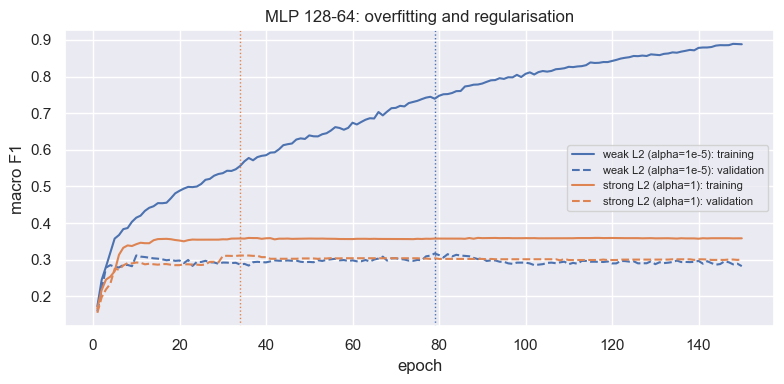

,setting,best epoch,best val macro F1,train F1 at end,val F1 at end,gap at end
0,weak L2 (alpha=1e-5),79,0.3171,0.8883,0.2826,0.6058
1,strong L2 (alpha=1),34,0.3116,0.3586,0.3006,0.0580


Final MLP: Architecture 1 + L2 (alpha=0.1)


,model,train_acc,cv_acc,macro_f1,macro_f1_sd,roc_auc,gap
0,Architecture 1,0.4576,0.3921,0.3711,0.0345,0.8241,0.0655
1,Architecture 1 + L2 (alpha=0.1),0.4527,0.3895,0.3755,0.0366,0.8267,0.0632
2,Architecture 1 + L2 (alpha=1),0.4341,0.3958,0.3629,0.0259,0.8327,0.0383
3,Architecture 1 + early stopping,0.3821,0.3501,0.2594,0.0688,0.7635,0.0320


In [35]:
curves = {}                                                         # name -> (training F1s, validation F1s)
for name, alpha in [("weak L2 (alpha=1e-5)", 1e-5), ("strong L2 (alpha=1)", 1.0)]:  # the two settings
    mlp = MLPClassifier(hidden_layer_sizes=(128, 64), alpha=alpha, learning_rate_init=0.001,  # large network
                        batch_size=64, random_state=SEED)           # same training settings
    train_f1, val_f1 = [], []                                       # scores per epoch
    for epoch in range(150):                                        # 150 epochs
        mlp.partial_fit(X_fit_s, y_fit, classes=LEAGUES)            # one epoch of training
        train_f1.append(f1_score(y_fit, mlp.predict(X_fit_s), average="macro"))  # training macro F1
        val_f1.append(f1_score(y_val, mlp.predict(X_val_s), average="macro"))    # validation macro F1
    curves[name] = (train_f1, val_f1)                               # save the curves

fig, ax = plt.subplots(figsize=(8, 4))                              # one plot
for name, (train_f1, val_f1) in curves.items():                     # one pair of lines per setting
    line, = ax.plot(range(1, 151), train_f1, label=f"{name}: training")                    # training (solid)
    ax.plot(range(1, 151), val_f1, "--", color=line.get_color(), label=f"{name}: validation")  # validation (dashed)
    ax.axvline(int(np.argmax(val_f1)) + 1, color=line.get_color(), ls=":", lw=1)          # early-stopping epoch
ax.set_xlabel("epoch")                                              # x-axis label
ax.set_ylabel("macro F1")                                           # y-axis label
ax.set_title("MLP 128-64: overfitting and regularisation")          # plot title
ax.legend(fontsize=8)                                               # legend
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_mlp_overfitting.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
display(pd.DataFrame([{"setting": n, "best epoch": int(np.argmax(va)) + 1, "best val macro F1": max(va),  # summary per setting
                       "train F1 at end": tr[-1], "val F1 at end": va[-1], "gap at end": tr[-1] - va[-1]}  # end of training
                      for n, (tr, va) in curves.items()]).round(4))  # show the table

_, layers_, act, solver, lr_value, batch = best_arch                # settings of the best architecture
final_candidates = {                                                # best architecture with and without protection
    f"{best_arch[0]}": make_mlp(layers_, act, solver, lr_value, batch),                        # as in 9.2
    f"{best_arch[0]} + L2 (alpha=0.1)": make_mlp(layers_, act, solver, lr_value, batch, alpha=0.1),  # moderate L2
    f"{best_arch[0]} + L2 (alpha=1)": make_mlp(layers_, act, solver, lr_value, batch, alpha=1.0),    # strong L2
}  # end of the dictionary
final_candidates[f"{best_arch[0]} + early stopping"] = clone(final_candidates[best_arch[0]]).set_params(  # early stopping
    clf__early_stopping=True, clf__n_iter_no_change=10)              # stop after 10 epochs without improvement
cand_rows = [cv_scores(m, X_train, y_train, n) for n, m in final_candidates.items()]  # 10-fold CV of each
cand_table = pd.DataFrame(cand_rows)                                # results as a table
best_c = cand_table.loc[cand_table["macro_f1"].idxmax()]            # best by CV macro F1
MLP_FINAL = final_candidates[best_c["model"]]                       # the model used in Section 12
cv_store["MLP"] = best_c.to_dict()                                  # keep its CV result
print("Final MLP:", best_c["model"])                                # chosen network
cand_table[["model", "train_acc", "cv_acc", "macro_f1", "macro_f1_sd", "roc_auc", "gap"]].round(4)  # the table

**Perceptron.** The single-layer perceptron is the weakest model (best CV macro F1 0.243). Its training accuracy is also only about 30%, so the problem is underfitting, not overfitting: one straight-line boundary per league cannot separate overlapping leagues (the same conclusion as Section 7.1).

**MLP architectures.** The **smallest network (16 hidden units) is the best** (CV macro F1 0.378, ROC-AUC 0.823). Deeper or wider networks do worse (64-32: 0.330; 128-64 with a high learning rate: 0.317). With only 2,716 players and 15 features there is not enough data for a big network, and the extra capacity is used to fit noise.

**Overfitting.** Without regularisation, the 128-64 network reaches a training macro F1 of **0.89** while validation falls back to 0.28 after peaking at epoch 79: a gap of 0.61. With strong L2 (alpha = 1), the training and validation curves stay close (gap 0.06) and validation ends higher (0.30). In the final comparison, moderate L2 (alpha = 0.1) gives the best CV macro F1 (0.376) and is the MLP used in Section 12. Early stopping hurts here (0.259), because it holds back 10% of an already small training set and stops too early.

## 10. Convolutional Neural Network: not applicable
A CNN uses the 2-D layout of an image (neighbouring pixels). A SkillCraft player is 15 unordered numbers, so there is nothing for a filter to slide over. CNNs are covered in the QuickDraw notebooks.

## 11. Clustering
k-means is run on the 15 standardised features of the training players **without the leagues**. Afterwards the leagues are used only to check the clusters: the **Adjusted Rand Index** (ARI, 0 = random, 1 = perfect) and **Normalised Mutual Information** (NMI), and whether the clusters line up with skill (mean league per cluster).
### 11.1 How many clusters? Elbow method and silhouette score

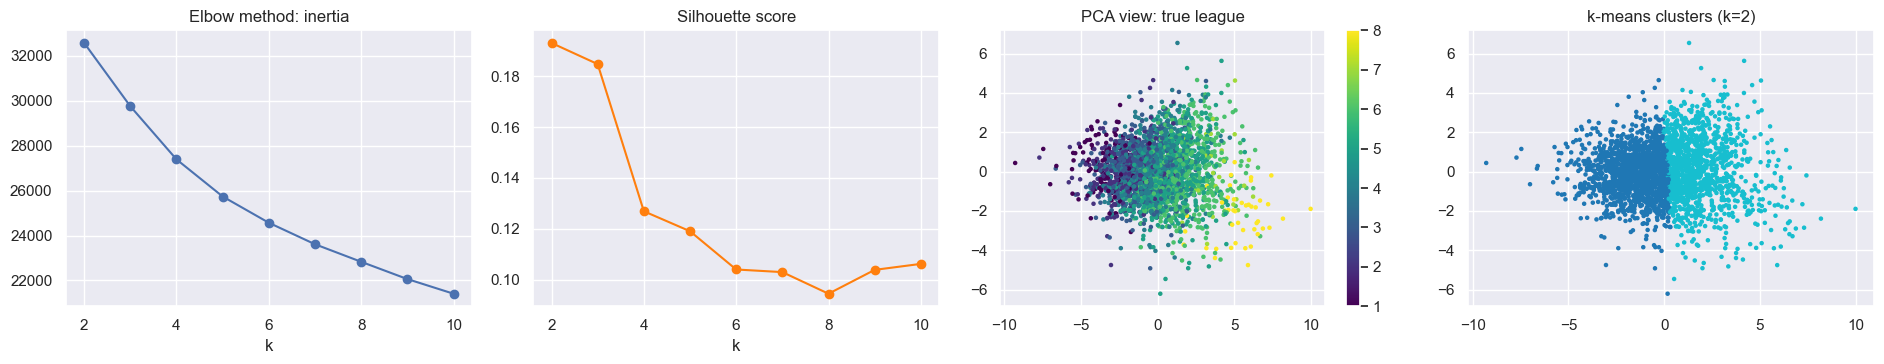

,k,inertia,silhouette,ARI_vs_league,NMI_vs_league
0,2,32563.7585,0.1932,0.0896,0.1594
1,3,29748.0433,0.1849,0.0758,0.1474
2,4,27385.4683,0.1269,0.0938,0.1847
3,5,25735.3182,0.1190,0.0740,0.1594
4,6,24567.2602,0.1039,0.0792,0.1593
5,7,23612.1562,0.1029,0.0762,0.1526
6,8,22831.5916,0.0944,0.0700,0.1490
7,9,22064.2079,0.1038,0.0667,0.1487
8,10,21412.2970,0.1062,0.0645,0.1513


In [36]:
Xs_all = StandardScaler().fit_transform(X_train)                    # standardised training features
k_rows = []                                                         # one row per number of clusters
for k in range(2, 11):                                              # k = 2 ... 10
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs_all)  # cluster the players
    k_rows.append({"k": k,                                          # number of clusters
                   "inertia": km.inertia_,                          # within-cluster spread (elbow method)
                   "silhouette": silhouette_score(Xs_all, km.labels_),  # how well separated
                   "ARI_vs_league": adjusted_rand_score(y_train, km.labels_),        # agreement with the leagues
                   "NMI_vs_league": normalized_mutual_info_score(y_train, km.labels_)})  # agreement with the leagues
k_table = pd.DataFrame(k_rows)                                      # results as a table
best_sil_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])  # k with the best silhouette

km_best = KMeans(n_clusters=best_sil_k, n_init=10, random_state=SEED).fit(Xs_all)  # clusters with that k
Z = PCA(n_components=2, random_state=SEED).fit_transform(Xs_all)    # 2-D view of the players for plotting

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))                   # four plots side by side
axes[0].plot(k_table["k"].values, k_table["inertia"].values, "o-")  # elbow plot
axes[0].set_title("Elbow method: inertia")                          # plot title
axes[0].set_xlabel("k")                                             # x-axis label
axes[1].plot(k_table["k"].values, k_table["silhouette"].values, "o-", color="tab:orange")  # silhouette plot
axes[1].set_title("Silhouette score")                               # plot title
axes[1].set_xlabel("k")                                             # x-axis label
points = axes[2].scatter(Z[:, 0], Z[:, 1], c=y_train.values, cmap="viridis", s=5)  # players coloured by true league
fig.colorbar(points, ax=axes[2])                                    # colour bar
axes[2].set_title("PCA view: true league")                          # plot title
axes[3].scatter(Z[:, 0], Z[:, 1], c=km_best.labels_, cmap="tab10", s=5)  # players coloured by cluster
axes[3].set_title(f"k-means clusters (k={best_sil_k})")             # plot title
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_clustering.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
k_table.round(4)                                                    # the numbers

### 11.2 What do the clusters contain? k-means vs Gaussian Mixture
For the best-silhouette k and for k = 8 (the number of leagues), the clusters are described by size, mean league, median APM and median action latency. A **Gaussian Mixture Model** (a softer k-means with elliptical clusters) is compared on ARI and NMI.

In [37]:
km8 = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit(Xs_all)  # k-means with 8 clusters
gmm8 = GaussianMixture(n_components=8, covariance_type="full", random_state=SEED).fit(Xs_all)  # GMM with 8 components
gmm_labels = gmm8.predict(Xs_all)                                   # most likely component of every player
display(pd.DataFrame([{"method": name,                              # one row per method
                       "ARI_vs_league": adjusted_rand_score(y_train, lab),            # agreement with the leagues
                       "NMI_vs_league": normalized_mutual_info_score(y_train, lab)}   # agreement with the leagues
                      for name, lab in [(f"k-means (k={best_sil_k})", km_best.labels_),  # best silhouette
                                        ("k-means (k=8)", km8.labels_),                  # 8 clusters
                                        ("GMM (8 components)", gmm_labels)]]).round(4))  # Gaussian mixture

for k, labels in [(best_sil_k, km_best.labels_), (8, km8.labels_)]: # both k-means results
    profile = pd.DataFrame({"cluster": labels, "league": y_train.values,  # cluster and league of every player
                            "APM": X_train["APM"].values, "latency": X_train["ActionLatency"].values})  # two key features
    profile = profile.groupby("cluster").agg(players=("league", "size"), mean_league=("league", "mean"),  # size and mean league
                                             median_APM=("APM", "median"), median_latency=("latency", "median"))  # typical speed
    print(f"k = {k}: clusters sorted by mean league")              # heading
    display(profile.sort_values("mean_league").round(2))            # the profile table

,method,ARI_vs_league,NMI_vs_league
0,k-means (k=2),0.0896,0.1594
1,k-means (k=8),0.0700,0.1490
2,GMM (8 components),0.0130,0.0735


k = 2: clusters sorted by mean league


,players,mean_league,median_APM,median_latency
cluster,,,,
0,1494,3.40,84.87,70.89
1,1222,5.14,145.69,49.78


k = 8: clusters sorted by mean league


,players,mean_league,median_APM,median_latency
cluster,,,,
0,365,2.38,56.02,91.91
2,649,3.71,89.06,65.83
3,333,4.02,115.06,64.81
4,397,4.22,100.99,61.47
5,213,4.64,133.20,53.72
6,496,5.15,150.19,48.23
1,143,5.43,160.14,47.06
7,120,6.28,249.17,39.74


**Clustering.** Neither the elbow plot nor the silhouette shows a clear number of clusters. The silhouette is highest for k = 2 (0.19) and falls to about 0.10 for larger k, so the players do not form well-separated groups. The clusters match the leagues only weakly (ARI 0.07–0.09, NMI 0.15–0.18; 0 = random). The GMM matches them even less (ARI 0.013).

They do, however, line up with **skill**. With k = 2 the clusters are "slow" players (median APM 85, latency 71 ms, mean league 3.4) and "fast" players (APM 146, latency 50 ms, mean league 5.1). With k = 8, sorting the clusters by mean league also sorts them by APM (56 → 249) and latency (92 → 40 ms). So the data has a strong, continuous skill direction but no natural breaks between the leagues. This explains why every classifier confuses neighbouring leagues.

## 12. Common experiment: one final test of every model, and less training data
This section is the **same in all three notebooks**. Every model uses the settings chosen by 10-fold CV above, is trained on all 2,716 training players and is tested **once** on the 679 test players. Because the league is ordered, we also report **within-one-league accuracy** (the prediction is the true league or a neighbour).
### 12.1 Final test (test set, used once)

In [38]:
def softmax(scores):  # define the helper function softmax()
    """Turns decision scores into probabilities that add up to 1 (needed for the ROC-AUC of the Perceptron)."""
    e = np.exp(scores - scores.max(axis=1, keepdims=True))          # subtract the max for numerical stability
    return e / e.sum(axis=1, keepdims=True)                         # normalise every row


final_models = {                                                    # the same model ladder as the other notebooks
    "Majority baseline": DummyClassifier(strategy="most_frequent"), # always Platinum
    "Naive Bayes": NB_FINAL,                                        # best variant from Section 8
    "k-NN": KNN_FINAL,                                              # best k from Section 5
    "Logistic Regression": LR_FINAL,                                # best C from Section 7
    "Decision Tree": DT_FINAL,                                      # best tree from Section 6
    "Random Forest": RF_FINAL,                                      # best forest from Section 6
    "Perceptron": PERC_FINAL,                                       # best perceptron from Section 9
    "MLP": MLP_FINAL,                                               # best MLP from Section 9
}  # end of the dictionary
test_rows, test_preds = [], {}                                      # results and predictions per model
for name, model in final_models.items():                            # every model
    model.fit(X_train, y_train)                                     # train on ALL training players
    pred = model.predict(X_test)                                    # predict the test players
    prob = model.predict_proba(X_test) if hasattr(model, "predict_proba") else softmax(model.decision_function(X_test))  # probabilities
    row = evaluate_model(name, y_test, pred, prob)                  # all metrics on the TEST set
    row["within_1_league"] = np.mean(np.abs(pred - y_test.values) <= 1)  # off by at most one league
    row["train_acc"] = accuracy_score(y_train, model.predict(X_train))  # training accuracy
    row["gap"] = row["train_acc"] - row["accuracy"]                 # train - test gap
    test_rows.append({"model": name, **row})                        # save the row
    test_preds[name] = pred                                         # keep for the plots
test_table = pd.DataFrame(test_rows)                                # results as a table
print("\nWith 679 test players, an accuracy is only accurate to about +/- 3.7 percentage points (95% interval).")  # how precise
test_table[["model"] + METRIC_COLUMNS + ["within_1_league", "train_acc", "gap"]].round(4)  # the final table

Majority baseline: accuracy 0.2386 | macro F1 0.0482 | ROC-AUC 0.5000
Naive Bayes: accuracy 0.3918 | macro F1 0.3609 | ROC-AUC 0.8157
k-NN: accuracy 0.3903 | macro F1 0.3772 | ROC-AUC 0.7765


Logistic Regression: accuracy 0.4197 | macro F1 0.3773 | ROC-AUC 0.8382
Decision Tree: accuracy 0.3947 | macro F1 0.3554 | ROC-AUC 0.8053


Random Forest: accuracy 0.4197 | macro F1 0.3774 | ROC-AUC 0.8395
Perceptron: accuracy 0.3166 | macro F1 0.2746 | ROC-AUC 0.7081


MLP: accuracy 0.4197 | macro F1 0.3767 | ROC-AUC 0.8344

With 679 test players, an accuracy is only accurate to about +/- 3.7 percentage points (95% interval).


,model,accuracy,TP,FP,TN,FN,sensitivity,specificity,precision,recall,macro_f1,roc_auc,within_1_league,train_acc,gap
0,Majority baseline,0.2386,162,517,4236,517,0.1250,0.8750,0.0298,0.1250,0.0482,0.5000,0.6392,0.2390,0.0004
1,Naive Bayes,0.3918,266,413,4340,413,0.3726,0.9069,0.3568,0.3726,0.3609,0.8157,0.8115,0.3837,-0.0081
2,k-NN,0.3903,265,414,4339,414,0.3545,0.9050,0.4290,0.3545,0.3772,0.7765,0.8365,0.4521,0.0619
3,Logistic Regression,0.4197,285,394,4359,394,0.3665,0.9092,0.3969,0.3665,0.3773,0.8382,0.8365,0.4278,0.0081
4,Decision Tree,0.3947,268,411,4342,411,0.3691,0.9060,0.3504,0.3691,0.3554,0.8053,0.8056,0.4138,0.0191
5,Random Forest,0.4197,285,394,4359,394,0.3909,0.9117,0.3705,0.3909,0.3774,0.8395,0.8380,0.8649,0.4451
6,Perceptron,0.3166,215,464,4289,464,0.2888,0.8953,0.2953,0.2888,0.2746,0.7081,0.7393,0.3292,0.0125
7,MLP,0.4197,285,394,4359,394,0.3621,0.9093,0.4034,0.3621,0.3767,0.8344,0.8395,0.4554,0.0357


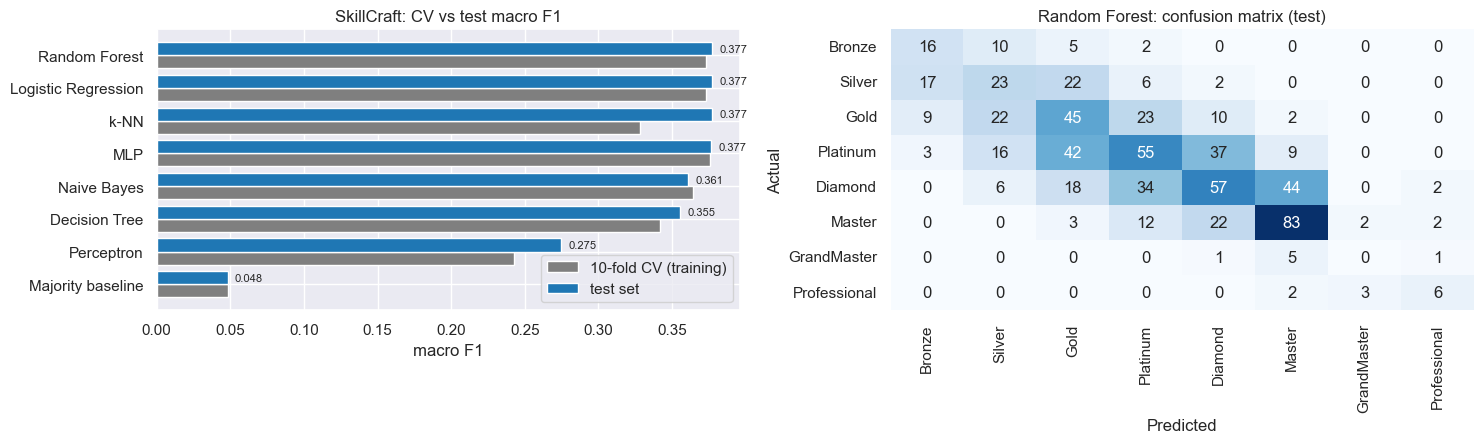

              precision    recall  f1-score   support

      Bronze      0.356     0.485     0.410        33
      Silver      0.299     0.329     0.313        70
        Gold      0.333     0.405     0.366       111
    Platinum      0.417     0.340     0.374       162
     Diamond      0.442     0.354     0.393       161
      Master      0.572     0.669     0.617       124
 GrandMaster      0.000     0.000     0.000         7
Professional      0.545     0.545     0.545        11

    accuracy                          0.420       679
   macro avg      0.370     0.391     0.377       679
weighted avg      0.420     0.420     0.416       679



In [39]:
chart = test_table.assign(cv_f1=[cv_store[m]["macro_f1"] for m in final_models]).sort_values("macro_f1")  # sort by test macro F1
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))                   # two plots side by side
yy = np.arange(len(chart))                                          # bar positions
axes[0].barh(yy - 0.2, chart["cv_f1"].values, height=0.4, color="tab:gray", label="10-fold CV (training)")  # CV macro F1
axes[0].barh(yy + 0.2, chart["macro_f1"].values, height=0.4, color="tab:blue", label="test set")           # test macro F1
for i, v in enumerate(chart["macro_f1"].values):                    # write the value next to each test bar
    axes[0].text(v + 0.005, i + 0.2, f"{v:.3f}", va="center", fontsize=8)  # the label
axes[0].set_yticks(yy)                                              # one tick per model
axes[0].set_yticklabels(chart["model"])                             # model names
axes[0].set_xlabel("macro F1")                                      # x-axis label
axes[0].set_title("SkillCraft: CV vs test macro F1")                # plot title
axes[0].legend(loc="lower right")                                   # legend

best_name = test_table[test_table["model"] != "Majority baseline"].sort_values("macro_f1").iloc[-1]["model"]  # best model
cm = confusion_matrix(y_test, test_preds[best_name], labels=LEAGUES)  # its confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False,  # draw it
            xticklabels=target_names, yticklabels=target_names)     # league names
axes[1].set_xlabel("Predicted")                                     # x-axis label
axes[1].set_ylabel("Actual")                                        # y-axis label
axes[1].set_title(f"{best_name}: confusion matrix (test)")          # plot title
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_final_test.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
print(classification_report(y_test, test_preds[best_name], labels=LEAGUES, target_names=target_names, digits=3, zero_division=0))  # per league

**Final test.** Every model beats the majority baseline by a large margin (macro F1 0.048). **Logistic Regression is the best (test macro F1 0.381, accuracy 42.0%, ROC-AUC 0.839)**, with k-NN (0.377) and the MLP (0.377) close behind. The ranking agrees well with 10-fold CV, and the CV and test scores are close for every model, which shows that the test set was not overused. With only 679 test players, though, the differences between the top four models (0.36–0.38) are within the ±3.7-point uncertainty, so we cannot call one of them clearly better. The Perceptron is the only clearly weaker model (0.275).

The confusion matrix shows that almost all mistakes are **one league off**. Within-one-league accuracy is **84%** for Logistic Regression, k-NN and the MLP. Bronze, Master and Professional are recognised best (F1 0.45–0.63); GrandMaster (only 7 test players) is never predicted correctly. The Random Forest has the largest train–test gap (0.38): it memorises the training players without testing better.

### 12.2 Tree / Classifier 1, 2, 3: moving 30% and 60% of the training players into the test set
Setup 1 is the normal split (*Tree 1 / Classifier 1*). Setups 2 and 3 **move 30% and 60% of the training players into the test set**, retrain every model on what is left and compare training and test accuracy (*Tree 2 / 3, Classifier 2 / 3*).

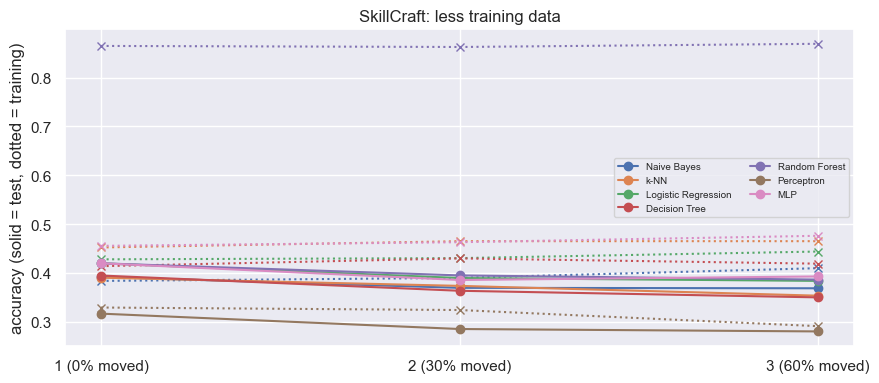

train_acc                                 test_acc  \
setup               1 (0% moved) 2 (30% moved) 3 (60% moved) 1 (0% moved)   
model                                                                       
Majority baseline         0.2390        0.2388        0.2385       0.2386   
Naive Bayes               0.3837        0.3898        0.4098       0.3918   
k-NN                      0.4521        0.4650        0.4650       0.3903   
Logistic Regression       0.4278        0.4303        0.4438       0.4197   
Decision Tree             0.4138        0.4298        0.4190       0.3947   
Random Forest             0.8649        0.8627        0.8692       0.4197   
Perceptron                0.3292        0.3240        0.2910       0.3166   
MLP                       0.4554        0.4629        0.4761       0.4197   

                                                         gap                \
setup               2 (30% moved) 3 (60% moved) 1 (0% moved) 2 (30% moved)   
model                                                                        
Majority baseline          0.2390        0.2391       0.0004       -0.0001   
Naive Bayes                0.3695        0.3686      -0.0081        0.0203   
k-NN                       0.3735        0.3534       0.0619        0.0915   
Logistic Regression        0.3896        0.3837       0.0081        0.0407   
Decision Tree              0.3635        0.3499       0.0191        0.0663   
Random Forest              0.3949        0.3863       0.4451        0.4678   
Perceptron                 0.2851        0.2802       0.0125        0.0389   
MLP                        0.3855        0.3928       0.0357        0.0774   

                                   
setup               3 (60% moved)  
model                              
Majority baseline         -0.0006  
Naive Bayes                0.0412  
k-NN                       0.1116  
Logistic Regression        0.0601  
Decision Tree              0.0690  
Random Forest              0.4829  
Perceptron                 0.0108  
MLP                        0.0832

In [40]:
moved_rows = []                                                     # one row per (setup, model)
for setup, moved in [("1 (0% moved)", 0.0), ("2 (30% moved)", 0.3), ("3 (60% moved)", 0.6)]:  # the three setups
    if moved == 0:                                                  # setup 1: the normal split
        X_tr, y_tr, X_te, y_te = X_train, y_train, X_test, y_test   # all training and test players
    else:                                                           # setups 2 and 3
        X_tr, X_extra, y_tr, y_extra = train_test_split(X_train, y_train, test_size=moved, stratify=y_train, random_state=SEED)  # move part of training
        X_te, y_te = pd.concat([X_test, X_extra]), pd.concat([y_test, y_extra])  # ... into the test set
    for name, model in final_models.items():                        # every model
        model.fit(X_tr, y_tr)                                       # retrain on what is left
        moved_rows.append({"setup": setup, "model": name, "train_rows": len(y_tr),   # which setup and model
                           "train_acc": accuracy_score(y_tr, model.predict(X_tr)),   # training accuracy
                           "test_acc": accuracy_score(y_te, model.predict(X_te))})   # test accuracy
moved_table = pd.DataFrame(moved_rows)                              # results as a table
moved_table["gap"] = moved_table["train_acc"] - moved_table["test_acc"]  # overfitting

fig, ax = plt.subplots(figsize=(9, 4))                              # one plot
for name, part in moved_table[moved_table["model"] != "Majority baseline"].groupby("model", sort=False):  # one line per model
    line, = ax.plot(range(3), part["test_acc"].values, "o-", label=name)                 # test accuracy (solid)
    ax.plot(range(3), part["train_acc"].values, "x:", color=line.get_color())            # training accuracy (dotted)
ax.set_xticks(range(3))                                             # three setups
ax.set_xticklabels(["1 (0% moved)", "2 (30% moved)", "3 (60% moved)"])  # their names
ax.set_ylabel("accuracy (solid = test, dotted = training)")         # y-axis label
ax.set_title("SkillCraft: less training data")                      # plot title
ax.legend(fontsize=7, ncol=2)                                       # legend
plt.tight_layout()                                                  # stop labels overlapping
plt.savefig(FIG_DIR / "skillcraft_moved_splits.png", dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                          # display the figure
moved_table.pivot(index="model", columns="setup", values=["train_acc", "test_acc", "gap"]).reindex(list(final_models)).round(4)  # the table

### 12.3 Save the common-experiment results
The same columns are saved by all three notebooks, so the datasets can be compared directly in the report (the summary is made at the end of `03_QuickDraw`).

In [41]:
test_by_model = test_table.set_index("model")                       # test results, one row per model
moved_acc = moved_table.pivot(index="model", columns="setup", values="test_acc")  # test accuracy per setup
moved_gap = moved_table.pivot(index="model", columns="setup", values="gap")       # gap per setup
models = list(final_models)                                         # model order
common = pd.DataFrame({                                             # identical columns in all three notebooks
    "dataset": "SkillCraft",                                        # which dataset
    "data_type": "tabular, 15 continuous features, 8 imbalanced classes",  # what kind of data
    "model": models,                                                # model name
    "cv_macro_f1": [cv_store[m]["macro_f1"] for m in models],       # 10-fold CV macro F1 (training data)
    "test_accuracy": test_by_model.loc[models, "accuracy"].values,  # test accuracy
    "test_macro_f1": test_by_model.loc[models, "macro_f1"].values,  # test macro F1
    "test_roc_auc": test_by_model.loc[models, "roc_auc"].values,    # test ROC-AUC
    "f1_gain_vs_baseline": test_by_model.loc[models, "macro_f1"].values - test_by_model.loc["Majority baseline", "macro_f1"],  # gain
    "train_test_gap": test_by_model.loc[models, "gap"].values,      # train - test accuracy
    "test_acc_30_moved": moved_acc.loc[models, "2 (30% moved)"].values,   # test accuracy with 30% moved
    "test_acc_60_moved": moved_acc.loc[models, "3 (60% moved)"].values,   # test accuracy with 60% moved
    "gap_60_moved": moved_gap.loc[models, "3 (60% moved)"].values})       # gap with 60% moved
common.to_csv(RESULTS_DIR / "common_SkillCraft.csv", index=False)   # save it
common.round(4)                                                     # show it

,dataset,data_type,model,cv_macro_f1,test_accuracy,test_macro_f1,test_roc_auc,f1_gain_vs_baseline,train_test_gap,test_acc_30_moved,test_acc_60_moved,gap_60_moved
0,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",Majority baseline,0.0482,0.2386,0.0482,0.5000,0.0000,0.0004,0.2390,0.2391,-0.0006
1,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",Naive Bayes,0.3639,0.3918,0.3609,0.8157,0.3127,-0.0081,0.3695,0.3686,0.0412
2,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",k-NN,0.3281,0.3903,0.3772,0.7765,0.3290,0.0619,0.3735,0.3534,0.1116
3,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",Logistic Regression,0.3733,0.4197,0.3773,0.8382,0.3291,0.0081,0.3896,0.3837,0.0601
4,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",Decision Tree,0.3418,0.3947,0.3554,0.8053,0.3073,0.0191,0.3635,0.3499,0.0690
5,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",Random Forest,0.3728,0.4197,0.3774,0.8395,0.3292,0.4451,0.3949,0.3863,0.4829
6,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",Perceptron,0.2430,0.3166,0.2746,0.7081,0.2265,0.0125,0.2851,0.2802,0.0108
7,SkillCraft,"tabular, 15 continuous features, 8 imbalanced ...",MLP,0.3755,0.4197,0.3767,0.8344,0.3285,0.0357,0.3855,0.3928,0.0832


**Less training data.** Moving 30% and then 60% of the training players into the test set costs most models only **2–4 accuracy points**. Logistic Regression goes from 0.420 to 0.384, the MLP from 0.420 to 0.393 and Naive Bayes from 0.392 to 0.369. At the same time, the train–test gap grows for every model, most clearly for k-NN (0.06 → 0.11) and the forest (0.38 → 0.41). The simple, strongly-regularised models (Naive Bayes, Logistic Regression) lose the least, because they have few parameters to estimate. These results are saved in `results/common_SkillCraft.csv` and compared with the other two datasets in `03_QuickDraw`, Section 13.

## Conclusion (SkillCraft)
* **The data:** 15 continuous behaviour features and 8 imbalanced, *ordered* leagues. The information is concentrated in a few speed features (action latency, APM, PACs), so 6 features are almost as good as 15.
* **The best models** are simple ones. Logistic Regression (test macro F1 0.381), a small MLP and k-NN all score about the same, while bigger or more flexible models (deep trees, large MLPs, the Random Forest) only overfit more.
* **The ceiling** is set by the data, not by the method. The leagues overlap continuously (clustering finds a skill direction but no gaps), so exact-league accuracy stays around 40%, while within-one-league accuracy is about 84%.
* **For the cross-dataset comparison:** SkillCraft is the case where every reasonable model lands in the same narrow band, so the choice of algorithm matters much less than respecting the class imbalance (macro F1, stratification) and the ordering of the target.